> ## 🧭 Bản đồ tổng quan notebook (đọc trước khi chạy)
>
> **Notebook này làm gì?** Nó nhận dữ liệu đã ghép ở bước 02 (mỗi dòng = 1 bản ghi gồm ảnh + metadata) và biến nó thành **dữ liệu sạch** cho 2 bài toán. Vấn đề cốt lõi: dataset GVLiD có rất nhiều **ảnh trùng** (>1.500 bản ghi, 446 nhóm), nếu không xử lý thì kết quả cả 2 bài đều sai lệch.
>
> **Luồng xử lý:**
>
> | Bước | Mục | Việc làm | Vì sao cần |
> |---|---|---|---|
> | 1 | 3 | Tính MD5 từng ảnh, gom nhóm ảnh giống hệt | Biết ảnh nào trùng |
> | 2 | 4 | Loại nhóm mâu thuẫn nhãn, khử trùng | Tránh nhiễu nhãn và rò rỉ train/test |
> | 3 | 4.1 | Kiểm tra metadata trong nhóm trùng | Biết metadata có gắn chặt với ảnh không (ảnh hưởng Bài 2) |
> | 4 | 5, 5.1 | Đo chất lượng ảnh, đối chiếu với metadata | Phát hiện "đường tắt" và metadata không đáng tin |
> | 5 | 6 | Tìm ảnh **gần** trùng (dHash) | MD5 chỉ bắt được trùng từng byte |
> | 6 | 6.1 | Kiểm chứng bằng so sánh điểm ảnh, loại nhóm gần trùng khác lớp, mỗi nhóm giữ 1 ảnh | Nhãn không xác minh được thì không dùng; tránh rò rỉ qua ảnh nén lại/lật |
> | 7 | 7 | Chia Train/Val/Test và 5 Fold, tính class weight | Chuẩn bị huấn luyện, xử lý mất cân bằng lớp |
> | 8 | 8 | Trích 25 đặc trưng thủ công | Dùng cho SVM, RF, XGBoost, KNN |
> | 9 | 9 | Xuất CSV/JSON | Cho notebook Bài 1 và Bài 2 đọc |
>
> **Thuật ngữ nhanh**
> - **MD5**: "dấu vân tay" của tệp. Hai tệp giống từng byte thì MD5 giống nhau. Khác 1 pixel (nén lại, resize) là MD5 khác.
> - **Data leakage (rò rỉ dữ liệu)**: cùng một ảnh nằm ở cả train và test, mô hình "thuộc bài" nên điểm cao ảo.
> - **Nhóm mâu thuẫn nhãn**: cùng một ảnh nhưng nằm ở nhiều thư mục bệnh khác nhau.
> - **Khử trùng (dedup)**: mỗi ảnh giống hệt chỉ giữ 1 đại diện.
>
> **Thứ tự chạy:** chạy tuần tự từ trên xuống (Run All). Các cell sau dùng biến của cell trước (`df`, `df_consistent`, `df_task1`...), nên không nhảy cóc.

# SMART VINEYARD
## 03. TIỀN XỬ LÝ ẢNH & CHUẨN BỊ DỮ LIỆU (IMAGE PREPROCESSING)

### 1. Mục tiêu
- Đọc dữ liệu đã ghép từ bước `02_DataMatching` (`image_metadata.json`).
- Băm MD5 toàn bộ ảnh để định danh các nhóm ảnh trùng lặp và kiểm tra tính nhất quán của nhãn.
- Loại bỏ hoàn toàn các nhóm ảnh bị mâu thuẫn nhãn (cùng 1 bức ảnh nhưng gán nhiều loại bệnh khác nhau).
- Tìm ảnh **gần** trùng bằng dHash, kiểm chứng bằng so sánh điểm ảnh; loại các nhóm gần trùng bị gán nhiều lớp (không xác minh được nhãn đúng), mỗi nhóm còn lại chỉ giữ 1 ảnh nét nhất.
- **Tách luồng dữ liệu chuẩn cho 2 bài toán**:
  - **Bài toán 1 (Phân loại bệnh qua ảnh lá nho)**: Khử trùng tuyệt đối (mỗi mã MD5 và mỗi nhóm gần trùng giữ 1 ảnh đại diện), đánh giá chất lượng thị giác (Độ sáng, Độ tương phản, Độ mờ Laplacian, thống kê kênh màu RGB), trích xuất đặc trưng bàn tay (Màu sắc HSV, Kết cấu GLCM, Hình dạng Hu Moments) và chia tập Train/Val/Test (70/15/15) đảm bảo không rò rỉ dữ liệu (Zero Data Leakage).
  - **Bài toán 2 (Phân tích phân bố bệnh & môi trường)**: Xuất bộ dữ liệu nhất quán (`task2_env_full.csv`) và bộ dữ liệu đối chứng đã khử trùng (`task2_env_dedup.csv`) phục vụ gom cụm vườn nho và khai phá luật kết hợp.

### 2. Import thư viện & Cấu hình đường dẫn

#### 📝 Giải thích cell: import & cấu hình
**Mục đích:** nạp thư viện và khai báo đường dẫn vào/ra.

**Từng phần:**
1. **Thư viện xử lý dữ liệu:** `pandas` (bảng), `numpy` (mảng số), `json`/`hashlib` (đọc metadata, băm MD5).
2. **Thư viện ảnh:** `cv2` (OpenCV) và `PIL` để đọc và biến đổi ảnh.
3. **Thư viện học máy:** `train_test_split`, `compute_class_weight` của scikit-learn.
4. **`RANDOM_STATE = 42`:** cố định hạt giống ngẫu nhiên để chia tập **lặp lại được** (chạy lại ra cùng kết quả).
5. **Đường dẫn:** `DATASET_DIR` là nơi chứa ảnh gốc, `MATCHED_JSON` là file đầu ra của bước 02, `STEP03_DIR` là nơi ghi kết quả bước này (`mkdir(..., exist_ok=True)` tạo thư mục nếu chưa có).
6. Hai dòng `print(... .exists())` giúp kiểm tra nhanh: nếu in `False` thì sai đường dẫn, **dừng lại sửa** trước khi chạy tiếp.

**Lưu ý:** `PROJECT_DIR` đang là đường dẫn Windows `D:\DataMining26\Smart-Vineyard`. Nếu chạy máy khác, sửa đúng dòng này.

In [2]:
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
RANDOM_STATE = 42

# Cấu hình đường dẫn đồng bộ với 02_DataMatching
PROJECT_DIR = Path(r"D:\DataMining26\Smart-Vineyard")
DATASET_DIR = (
    PROJECT_DIR
    / "Dataset"
    / "GVLiD GrapeVine Leaf identification of the Disease"
    / "DATASET"
)
PROCESSED_DIR = PROJECT_DIR / "outputs" / "processed"
MATCHED_JSON = PROCESSED_DIR / "image_metadata.json"

# Thư mục lưu kết quả đầu ra của bước 03
STEP03_DIR = PROCESSED_DIR / "step03_clean"
STEP03_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset tồn tại      :", DATASET_DIR.exists())
print("Matched JSON tồn tại :", MATCHED_JSON.exists())
print("Thư mục lưu bước 03  :", STEP03_DIR)

Dataset tồn tại      : True
Matched JSON tồn tại : True
Thư mục lưu bước 03  : D:\DataMining26\Smart-Vineyard\outputs\processed\step03_clean


### 3. Đọc dữ liệu ghép & Định danh nhóm ảnh trùng bằng MD5
Tính toán mã băm MD5 trên nội dung nhị phân của từng tệp ảnh để gom nhóm các ảnh giống hệt nhau và kiểm tra xem có nhóm ảnh nào bị gán nhiều nhãn bệnh khác nhau không.

#### 📝 Giải thích cell: đọc metadata & tính MD5
**Mục đích:** biết ảnh nào giống hệt nhau và nhóm đó có bị gán nhiều nhãn bệnh không.

**Từng bước:**
1. **Đọc `image_metadata.json`** thành bảng `df` (mỗi dòng = 1 bản ghi ảnh + metadata).
2. **`compute_md5`**: mở tệp ảnh ở chế độ nhị phân và đọc từng khối 1 MB để băm, nên không tốn RAM dù ảnh lớn. Kết quả là chuỗi 32 ký tự (MD5).
3. **Cột `MD5`**: ảnh có cùng MD5 là bản sao y hệt.
4. **`groupby("MD5")`** rồi tính hai số cho mỗi nhóm:
   - `Group_Size`: số bản ghi trong nhóm (1 = ảnh duy nhất, ≥2 = có trùng).
   - `Num_Classes`: số loại bệnh khác nhau trong nhóm. **>1 nghĩa là mâu thuẫn nhãn.**
5. **`Dup_Group_Id`**: đặt mã dễ nhớ `GRP_0001...`, sắp theo nhóm lớn nhất trước, nên `GRP_0001` là nhóm bị nhân bản nhiều nhất.
6. **`merge`** gắn các thông tin này ngược vào từng bản ghi trong `df`.
7. Các dòng `print` tóm tắt: tổng bản ghi, số ảnh độc nhất, số nhóm trùng, số nhóm mâu thuẫn.

**Vì sao MD5 mà không so pixel?** MD5 nhanh và chính xác tuyệt đối cho trùng *từng byte*. Trùng "gần giống" được xử lý ở mục 6 và 6.1.

In [3]:
with open(MATCHED_JSON, "r", encoding="utf-8") as f:
    df = pd.DataFrame(json.load(f))

def compute_md5(rel_path, chunk=1 << 20):
    full_path = DATASET_DIR / rel_path
    h = hashlib.md5()
    with open(full_path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

df["MD5"] = df["Image_Path"].apply(compute_md5)

# Thống kê kích thước nhóm trùng và số nhãn bệnh trong mỗi nhóm MD5
md5_stats = df.groupby("MD5").agg(
    Group_Size=("Sr_No", "count"),
    Num_Classes=("Disease_Type", "nunique")
).reset_index()

# Gán mã định danh nhóm (Dup_Group_Id) dễ theo dõi
md5_stats = md5_stats.sort_values(["Group_Size", "MD5"], ascending=[False, True]).reset_index(drop=True)
md5_stats["Dup_Group_Id"] = [f"GRP_{i+1:04d}" for i in range(len(md5_stats))]

df = df.merge(md5_stats, on="MD5", how="left")

print(f"Tổng số bản ghi đầu vào                           : {len(df)}")
print(f"Số lượng ảnh độc nhất (MD5 duy nhất)             : {df['MD5'].nunique()}")
print(f"Số nhóm có >= 2 ảnh trùng nhau                   : {(md5_stats['Group_Size'] > 1).sum()}")
print(f"Số nhóm bị mâu thuẫn nhãn (Num_Classes > 1)      : {(md5_stats['Num_Classes'] > 1).sum()}")

Tổng số bản ghi đầu vào                           : 3476
Số lượng ảnh độc nhất (MD5 duy nhất)             : 2409
Số nhóm có >= 2 ảnh trùng nhau                   : 446
Số nhóm bị mâu thuẫn nhãn (Num_Classes > 1)      : 2


- Từ 3.476 bản ghi chỉ có **2.409 ảnh khác nhau** (MD5 duy nhất): khoảng **1.067 bản ghi (≈31%) là bản sao** của ảnh khác. Có **446 nhóm** ảnh trùng, trong đó **2 nhóm bị mâu thuẫn nhãn** (cùng một ảnh nhưng nằm ở nhiều lớp).

### 4. Xử lý mâu thuẫn nhãn & Khử trùng dữ liệu (Deduplication)
- **Nhóm mâu thuẫn nhãn (`Num_Classes > 1`)**: Cùng một bức ảnh nhưng nằm ở 2 thư mục bệnh khác nhau $\rightarrow$ Loại bỏ hoàn toàn để tránh nhiễu nhãn.
- **Nhóm trùng cùng lớp (`Num_Classes == 1` và `Group_Size > 1`)**: Giữ lại 1 ảnh đại diện đầu tiên (`keep="first"`) cho Bài toán 1 để ngăn chặn học vẹt (Overfitting) và rò rỉ dữ liệu giữa tập Train và Test.

#### 📝 Giải thích cell: tách mâu thuẫn, tạo 3 tập dữ liệu
**Mục đích:** từ `df` thô tạo ra 3 tầng dữ liệu, mỗi tầng phục vụ một mục đích.

| Biến | Cách tạo | Dùng cho |
|---|---|---|
| `df` | Dữ liệu thô sau ghép | Chỉ tham chiếu |
| `df_consistent` | Bỏ các nhóm `Num_Classes > 1` | **Bài 2 (bản Full)**, chưa khử trùng |
| `df_task1` | `df_consistent` + mỗi MD5 giữ 1 bản đầu (`drop_duplicates(keep="first")`) | **Bài 1** và Bài 2 (bản Dedup) |

**Từng bước trong cell:**
1. Lọc `df_conflict` (các bản ghi mâu thuẫn nhãn) và in ra để kiểm tra bằng mắt.
2. In từng nhóm mâu thuẫn gồm những lớp nào, số lượng bao nhiêu.
3. Tạo `df_consistent`, rồi `df_task1`.
4. Dựng bảng `compare_dist` đặt cạnh nhau số mẫu mỗi lớp: **ban đầu → bỏ mâu thuẫn → sau khử trùng**, cùng tỷ lệ % và cột **"Tỷ lệ ảnh dư"** (bao nhiêu % bản ghi của lớp đó là bản sao).

**Vì sao loại hẳn nhóm mâu thuẫn?** Cùng một ảnh vừa là Black Rot vừa là Esca thì không thể biết nhãn nào đúng. Giữ lại sẽ dạy mô hình nhãn sai.

**Vì sao `keep="first"` an toàn?** Với Bài 1 chỉ cần *nhãn + ảnh*, các bản sao cùng lớp không thêm thông tin. Nhưng với Bài 2 thì bản ghi nào được giữ lại có thể làm đổi vườn, xem mục 4.1.

**Cách đọc bảng `compare_dist`:** cột "Tỷ lệ ảnh dư" càng cao thì lớp đó càng bị nhân bản, và nếu không khử trùng thì mô hình sẽ thấy lớp đó nhiều hơn thực tế.

In [4]:
# 1. Tách và kiểm tra các bản ghi bị mâu thuẫn nhãn
df_conflict = df[df["Num_Classes"] > 1].sort_values(["Dup_Group_Id", "Sr_No"]).copy()
print(f"Số bản ghi bị loại do mâu thuẫn nhãn: {len(df_conflict)}")
display(df_conflict[["Dup_Group_Id", "Sr_No", "Image_Name", "Disease_Type", "Location.Vineyard", "MD5"]])
print("\nCác lớp bị lẫn trong từng nhóm mâu thuẫn:")
print(df_conflict.groupby("Dup_Group_Id")["Disease_Type"].agg(lambda s: dict(s.value_counts())).to_string())

# 2. Tập dữ liệu nhất quán (Consistent Dataset - dùng cho Bài toán 2 Full)
df_consistent = df[df["Num_Classes"] == 1].sort_values(["Disease_Type", "Image_Number"]).reset_index(drop=True)
print(f"Số bản ghi nhất quán còn lại (Bài 2 - Full): {len(df_consistent)}")

# 3. Tập dữ liệu ảnh độc nhất (Unique Dataset - dùng cho Bài toán 1 & Bài toán 2 Đối chứng)
df_task1 = df_consistent.drop_duplicates(subset=["MD5"], keep="first").reset_index(drop=True)
print(f"Số ảnh độc nhất sau khi khử trùng (Bài 1 - Unique): {len(df_task1)}")

# Bảng đối chiếu phân bố lớp trước và sau khi khử trùng
compare_dist = pd.concat([
    df["Disease_Type"].value_counts().rename(f"Ban_dau ({len(df)})"),
    df_consistent["Disease_Type"].value_counts().rename(f"Bo_mau_thuan ({len(df_consistent)})"),
    df_task1["Disease_Type"].value_counts().rename(f"Sau_khu_trung ({len(df_task1)})"),
    (df_task1["Disease_Type"].value_counts(normalize=True) * 100).round(2).rename("Ty_le_Unique (%)")
], axis=1)
COL_RAW, COL_UNIQUE = compare_dist.columns[0], compare_dist.columns[2]
compare_dist["Ty_le_anh_du (%)"] = ((1 - compare_dist[COL_UNIQUE] / compare_dist[COL_RAW]) * 100).round(1)
display(compare_dist)

Số bản ghi bị loại do mâu thuẫn nhãn: 18


,Dup_Group_Id,Sr_No,Image_Name,Disease_Type,Location.Vineyard,MD5
791,GRP_0003,793,black rot793.jpg,Black Rot,Vineyard_18,008bb3e396058405013d3402a4b20561
792,GRP_0003,794,black rot794.jpg,Black Rot,Vineyard_16,008bb3e396058405013d3402a4b20561
793,GRP_0003,795,black rot795.jpg,Black Rot,Vineyard_17,008bb3e396058405013d3402a4b20561
794,GRP_0003,796,black rot796.jpg,Black Rot,Vineyard_4,008bb3e396058405013d3402a4b20561
795,GRP_0003,797,black rot797.jpg,Black Rot,Vineyard_20,008bb3e396058405013d3402a4b20561
796,GRP_0003,798,black rot798.jpg,Black Rot,Vineyard_6,008bb3e396058405013d3402a4b20561
797,GRP_0003,799,black rot799.jpg,Black Rot,Vineyard_12,008bb3e396058405013d3402a4b20561
798,GRP_0003,800,black rot800.jpg,Black Rot,Vineyard_28,008bb3e396058405013d3402a4b20561
808,GRP_0003,811,esca002.jpg,Esca,Vineyard_6,008bb3e396058405013d3402a4b20561
799,GRP_0004,801,black rot801.jpg,Black Rot,Vineyard_7,cdcf88c8e785c459d26520de92f6817d



Các lớp bị lẫn trong từng nhóm mâu thuẫn:
Dup_Group_Id
GRP_0003    {'Black Rot': 8, 'Esca': 1}
GRP_0004    {'Black Rot': 8, 'Esca': 1}
Số bản ghi nhất quán còn lại (Bài 2 - Full): 3458
Số ảnh độc nhất sau khi khử trùng (Bài 1 - Unique): 2407


,Ban_dau (3476),Bo_mau_thuan (3458),Sau_khu_trung (2407),Ty_le_Unique (%),Ty_le_anh_du (%)
Disease_Type,,,,,
Healthy,1109,1109,1093,45.41,1.4
Esca,888,886,886,36.81,0.2
Black Rot,807,791,97,4.03,88.0
Leaf Blight,672,672,331,13.75,50.7


- **Hai nhóm mâu thuẫn nhãn (18 bản ghi):** `GRP_0003` gồm 8 ảnh Black Rot (`Sr_No` 793–800) và `esca002.jpg`; `GRP_0004` gồm 8 ảnh Black Rot (`Sr_No` 801–808) và `esca248.jpg`. Nghĩa là 2 ảnh trong thư mục Esca thực chất là bản sao của ảnh Black Rot. Loại toàn bộ 18 bản ghi là đúng vì không biết nhãn nào đúng.
- Cũng trong các nhóm này, 8 ảnh giống hệt nhau (`Sr_No` liên tiếp) lại gắn với **8 vườn khác nhau** (Vineyard_18, 16, 17, 4, 20, 6, 12, 28). Một bức ảnh không thể thuộc 8 vườn, nên đây là dấu hiệu metadata không gắn chặt với nội dung ảnh (xem mục 4.1).
- Sau khi bỏ mâu thuẫn còn **3.458** bản ghi, sau khi khử trùng còn **2.407** ảnh duy nhất.

| Lớp | Ban đầu | Sau khử trùng | Tỷ lệ ảnh dư |
|---|---|---|---|
| Healthy | 1.109 | 1.093 | ≈1% |
| Esca | 888 | 886 | ≈0% |
| Leaf Blight | 672 | 331 | ≈51% |
| **Black Rot** | 807 | **97** | **≈88%** |

- **Black Rot gần như chỉ có 97 ảnh gốc** (mỗi ảnh được nhân bản trung bình hơn 8 lần), Leaf Blight có khoảng một nửa là bản sao. Tỷ lệ ảnh duy nhất: Healthy 45,41%, Esca 36,81%, Leaf Blight 13,75%, Black Rot 4,03%, tức mất cân bằng **nặng**, khác hẳn kết luận "mất cân bằng nhẹ" ở EDA (tính trên số bản ghi thô).
- Tên cột `Bo_mau_thuan (3472)` và `Sau_khu_trung (2405)` trong output cũ là số viết cứng bị sai (số thật là 3.458 và 2.407). Cell đã được sửa để lấy số từ dữ liệu.

#### 📝 Giải thích cell: biểu đồ trước/sau khử trùng
**Mục đích:** nhìn trực quan lớp nào bị mất nhiều mẫu nhất khi khử trùng.

Hai cột cho mỗi lớp: xanh dương = số bản ghi ban đầu, xanh lá = số ảnh độc nhất. Cột xanh lá thấp hơn nhiều so với cột xanh dương nghĩa là lớp đó bị nhân bản nặng. `bar_label` ghi số lên đầu cột để đọc chính xác.

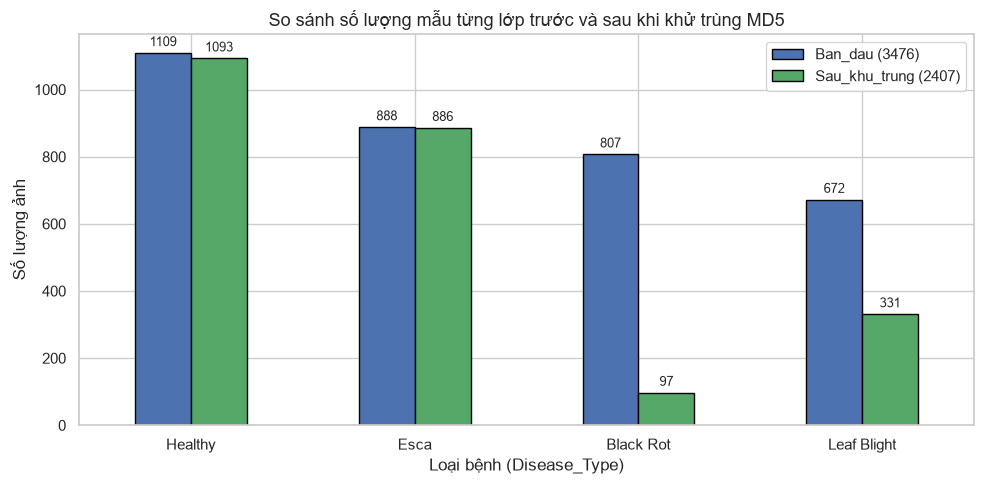

In [5]:
# Trực quan hóa phân bố nhãn trước và sau khi khử trùng
ax = compare_dist[[COL_RAW, COL_UNIQUE]].plot(
    kind="bar", figsize=(10, 5), color=["#4C72B0", "#55A868"], edgecolor="black"
)
plt.title("So sánh số lượng mẫu từng lớp trước và sau khi khử trùng MD5", fontsize=13)
plt.xlabel("Loại bệnh (Disease_Type)")
plt.ylabel("Số lượng ảnh")
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)
plt.tight_layout()
plt.show()

### 4.1. Kiểm tra metadata của các nhóm ảnh trùng

Cùng một bức ảnh **không thể** được chụp ở nhiều vườn, nhiều thời điểm hay nhiều điều kiện khác nhau. Vì vậy với mỗi nhóm ảnh trùng, so sánh metadata của các ảnh trong nhóm:
- **Giống hệt nhau:** bản ghi bị nhân bản, loại bớt là an toàn.
- **Khác nhau:** metadata không gắn chặt với nội dung ảnh (có thể được gán độc lập hoặc ngẫu nhiên). Khi đó việc giữ bản ghi nào khi khử trùng sẽ làm lệch số mẫu theo vườn, và cần thận trọng khi diễn giải các phân tích môi trường ở Bài 2.

Cell cũng so số vườn khác nhau quan sát được trong mỗi nhóm với số vườn kỳ vọng nếu vườn được gán ngẫu nhiên độc lập với ảnh.

#### 📝 Giải thích cell: metadata trong nhóm ảnh trùng có giống nhau không?
**Ý tưởng kiểm tra:** một bức ảnh chỉ chụp một lần ở một nơi, một thời điểm. Nếu nhiều bản sao của nó mang metadata **khác nhau** (vườn khác, thời tiết khác...) thì metadata **không gắn chặt** với ảnh.

**Từng bước:**
1. `meta_cols`: các thuộc tính cần so (vườn, thời tiết, ánh sáng, thời điểm chụp).
2. `dup_df`: chỉ lấy các nhóm có `Group_Size > 1`.
3. `groupby("MD5")[meta_cols].nunique()`: đếm số giá trị khác nhau của mỗi thuộc tính trong mỗi nhóm. Bằng 1 nghĩa là cả nhóm giống nhau.
4. `same_meta`: nhóm nào **mọi** thuộc tính đều bằng 1. In số nhóm giống hệt / khác nhau, và bảng số nhóm khác nhau theo từng thuộc tính.
5. **So với kỳ vọng ngẫu nhiên:** nếu mỗi bản sao được gán vườn hoàn toàn ngẫu nhiên trong `V` vườn, thì nhóm có `s` bản sao sẽ có trung bình `V × (1 − ((V−1)/V)^s)` vườn khác nhau. Cell in số vườn khác nhau **quan sát** cạnh số **kỳ vọng**.
6. In nhóm trùng lớn nhất để xem bằng mắt.

**Cách đọc:** nếu "quan sát" ≈ "kỳ vọng ngẫu nhiên" thì cột vườn **gần như được gán ngẫu nhiên**, nên mọi mối liên hệ vườn–bệnh ở Bài 2 sẽ rất yếu. Nếu "quan sát" gần 1 thì metadata nhất quán và đáng tin hơn.

In [6]:
meta_cols = [
    "Location.Vineyard",
    "Environmental_Conditions.Weather",
    "Environmental_Conditions.Lighting",
    "Environmental_Conditions.Time_of_Capture",
]

dup_df = df_consistent[df_consistent["Group_Size"] > 1]
g = dup_df.groupby("MD5")[meta_cols].nunique()
same_meta = (g == 1).all(axis=1)

print("Số nhóm trùng (đã bỏ nhóm mâu thuẫn nhãn):", len(g))
print("  - metadata GIỐNG HỆT nhau :", int(same_meta.sum()))
print("  - metadata KHÁC nhau      :", int((~same_meta).sum()))

print("\nSố nhóm có metadata khác nhau theo từng thuộc tính:")
display((g > 1).sum().rename("So_nhom_khac_nhau").to_frame())

# So số vườn khác nhau trong mỗi nhóm với kỳ vọng khi vườn được gán ngẫu nhiên
n_vineyards = df["Location.Vineyard"].nunique()
sizes = dup_df.groupby("MD5").size()
expected_distinct = n_vineyards * (1 - ((n_vineyards - 1) / n_vineyards) ** sizes)
print(f"\nSố vườn khác nhau trong mỗi nhóm trùng: quan sát TB = {g['Location.Vineyard'].mean():.2f} "
      f"| kỳ vọng nếu gán ngẫu nhiên = {expected_distinct.mean():.2f}")

# Ví dụ: nhóm trùng lớn nhất
big_md5 = sizes.idxmax()
print(f"\nNhóm trùng lớn nhất: {sizes.max()} ảnh giống hệt nhau")
display(
    dup_df[dup_df["MD5"] == big_md5][["Sr_No", "Image_Name", "Disease_Type"] + meta_cols].head(12)
)

Số nhóm trùng (đã bỏ nhóm mâu thuẫn nhãn): 444
  - metadata GIỐNG HỆT nhau : 1
  - metadata KHÁC nhau      : 443

Số nhóm có metadata khác nhau theo từng thuộc tính:


,So_nhom_khac_nhau
Location.Vineyard,425
Environmental_Conditions.Weather,325
Environmental_Conditions.Lighting,332
Environmental_Conditions.Time_of_Capture,329



Số vườn khác nhau trong mỗi nhóm trùng: quan sát TB = 3.10 | kỳ vọng nếu gán ngẫu nhiên = 3.12

Nhóm trùng lớn nhất: 16 ảnh giống hệt nhau


,Sr_No,Image_Name,Disease_Type,Location.Vineyard,Environmental_Conditions.Weather,Environmental_Conditions.Lighting,Environmental_Conditions.Time_of_Capture
119,121,black rot121.jpg,Black Rot,Vineyard_21,Windy,Natural sunlight,Evening
120,122,black rot122.jpg,Black Rot,Vineyard_27,Windy,Overcast,Morning
121,123,black rot123.jpg,Black Rot,Vineyard_14,Clear,Natural sunlight,Evening
122,124,black rot124.jpg,Black Rot,Vineyard_23,Clear,Overcast,Afternoon
123,125,black rot125.jpg,Black Rot,Vineyard_28,Humid,Natural sunlight,Evening
124,126,black rot126.jpg,Black Rot,Vineyard_17,Clear,Overcast,Evening
125,127,black rot127.jpg,Black Rot,Vineyard_2,Humid,Partly cloudy,Evening
126,128,black rot128.jpg,Black Rot,Vineyard_19,Humid,Natural sunlight,Morning
127,129,black rot129.jpg,Black Rot,Vineyard_5,Windy,Natural sunlight,Morning
128,130,black rot130.jpg,Black Rot,Vineyard_26,Humid,Overcast,Morning


### 5. Đánh giá chất lượng thị giác & Thống kê kênh màu RGB
Kiểm tra các chỉ số thị giác trên tập ảnh độc nhất (`df_task1`):
- **Độ sáng (`Brightness`)**: Trung bình cường độ sáng mức xám.
- **Độ tương phản (`Contrast`)**: Độ lệch chuẩn cường độ mức xám.
- **Độ sắc nét (`Blur_Laplacian`)**: Phương sai của toán tử Laplacian (giá trị quá thấp báo hiệu ảnh bị mờ/out nét).
- **Mean / Std kênh RGB**: Thông số chuẩn hóa (`Normalize`) đầu vào cho các mô hình Deep Learning.

#### 📝 Giải thích cell: đo chất lượng ảnh & thống kê RGB
**Mục đích:** đo các chỉ số thị giác cho từng ảnh độc nhất, và lấy mean/std RGB để chuẩn hóa ảnh cho Deep Learning.

**Từng bước trong `extract_image_quality`:**
1. **Đọc ảnh** bằng `np.fromfile` + `cv2.imdecode` thay vì `cv2.imread`, vì `imread` có thể lỗi với đường dẫn có tiếng Việt/khoảng trắng trên Windows.
2. Tạo bản **xám** (`img_gray`) và bản **RGB chia 255** (giá trị 0–1).
3. Tính 3 chỉ số trên ảnh xám:
   - `Brightness` = trung bình độ xám (cao = sáng).
   - `Contrast` = độ lệch chuẩn độ xám (cao = tương phản mạnh).
   - `Blur_Laplacian` = phương sai của Laplacian. Ảnh nét có nhiều cạnh nên phương sai lớn, ảnh mờ thì nhỏ.
4. Tính **mean và std của từng kênh R, G, B**.
5. `apply` chạy hàm cho mọi ảnh, `concat` ghép các cột mới vào `df_task1`.
6. `rgb_mean`, `rgb_std` là trung bình trên toàn tập, dùng làm tham số `Normalize` nếu train từ đầu.

**Vì sao chỉ tính trên `df_task1`?** Tính trên bản trùng sẽ tính lặp cùng một ảnh nhiều lần và làm lệch trung bình.

In [7]:
def extract_image_quality(rel_path):
    full_path = DATASET_DIR / rel_path
    # Sử dụng np.fromfile + cv2.imdecode để đọc an toàn mọi đường dẫn có khoảng trắng/tiếng Việt
    img_bytes = np.fromfile(str(full_path), dtype=np.uint8)
    img_bgr = cv2.imdecode(img_bytes, cv2.IMREAD_COLOR)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) / 255.0

    brightness = float(np.mean(img_gray))
    contrast = float(np.std(img_gray))
    blur_laplacian = float(cv2.Laplacian(img_gray, cv2.CV_64F).var())

    r_mean, g_mean, b_mean = np.mean(img_rgb, axis=(0, 1))
    r_std, g_std, b_std = np.std(img_rgb, axis=(0, 1))

    return pd.Series(
        [brightness, contrast, blur_laplacian, r_mean, g_mean, b_mean, r_std, g_std, b_std],
        index=["Brightness", "Contrast", "Blur_Laplacian", "R_mean", "G_mean", "B_mean", "R_std", "G_std", "B_std"]
    )

print("Đang tính toán chỉ số chất lượng ảnh trên tập ảnh độc nhất...")
quality_df = df_task1["Image_Path"].apply(extract_image_quality)
df_task1 = pd.concat([df_task1, quality_df], axis=1)

rgb_mean = df_task1[["R_mean", "G_mean", "B_mean"]].mean().round(4).tolist()
rgb_std = df_task1[["R_std", "G_std", "B_std"]].mean().round(4).tolist()

print(f"Thông số chuẩn hóa RGB (0..1) -> Mean: {rgb_mean} | Std: {rgb_std}")
display(df_task1[["Brightness", "Contrast", "Blur_Laplacian", "R_mean", "G_mean", "B_mean"]].describe().round(2))

Đang tính toán chỉ số chất lượng ảnh trên tập ảnh độc nhất...
Thông số chuẩn hóa RGB (0..1) -> Mean: [0.4658, 0.4949, 0.2657] | Std: [0.2295, 0.2314, 0.1882]


,Brightness,Contrast,Blur_Laplacian,R_mean,G_mean,B_mean
count,2407.00,2407.00,2407.00,2407.00,2407.00,2407.00
mean,117.31,55.89,255.00,0.47,0.49,0.27
std,18.28,10.40,251.20,0.08,0.08,0.09
min,52.02,21.00,3.82,0.20,0.22,0.08
25%,104.88,47.95,91.52,0.41,0.45,0.20
50%,116.79,57.72,207.53,0.46,0.49,0.25
75%,129.16,64.22,337.77,0.52,0.54,0.32
max,180.56,94.50,4804.54,0.72,0.78,0.60


- Độ sáng trung bình 117 (từ 52 đến 181), độ tương phản trung bình 56. Phương sai Laplacian có median ≈208 nhưng trải rất rộng (từ 3,8 đến 4.805), nên có ảnh rất mờ và vài ngoại lai rất sắc nét. Nên xem trực quan các ảnh ở hai đầu trước khi quyết định loại ảnh theo độ mờ.
- Thông số chuẩn hóa RGB tính trên ảnh duy nhất: mean [0,4658, 0,4949, 0,2657], std [0,2295, 0,2314, 0,1882]. Thành phần xanh dương thấp hơn nhiều so với ImageNet, nhưng khi fine-tune mô hình tiền huấn luyện vẫn nên dùng mean/std của ImageNet cho nhất quán với trọng số.

#### 📝 Giải thích cell: boxplot chất lượng theo lớp bệnh
**Mục đích:** xem ba chỉ số (độ sáng, tương phản, độ sắc nét) có khác nhau giữa các lớp không.

**Cách đọc boxplot:** hộp = 50% giữa dữ liệu, vạch trong hộp = trung vị, chấm lẻ = ngoại lai. Nếu các hộp của các lớp **lệch hẳn nhau** thì có thể mô hình sẽ phân loại bằng *điều kiện chụp* (sáng/tối) chứ không bằng *triệu chứng bệnh*. Đây gọi là "đường tắt" (shortcut learning).

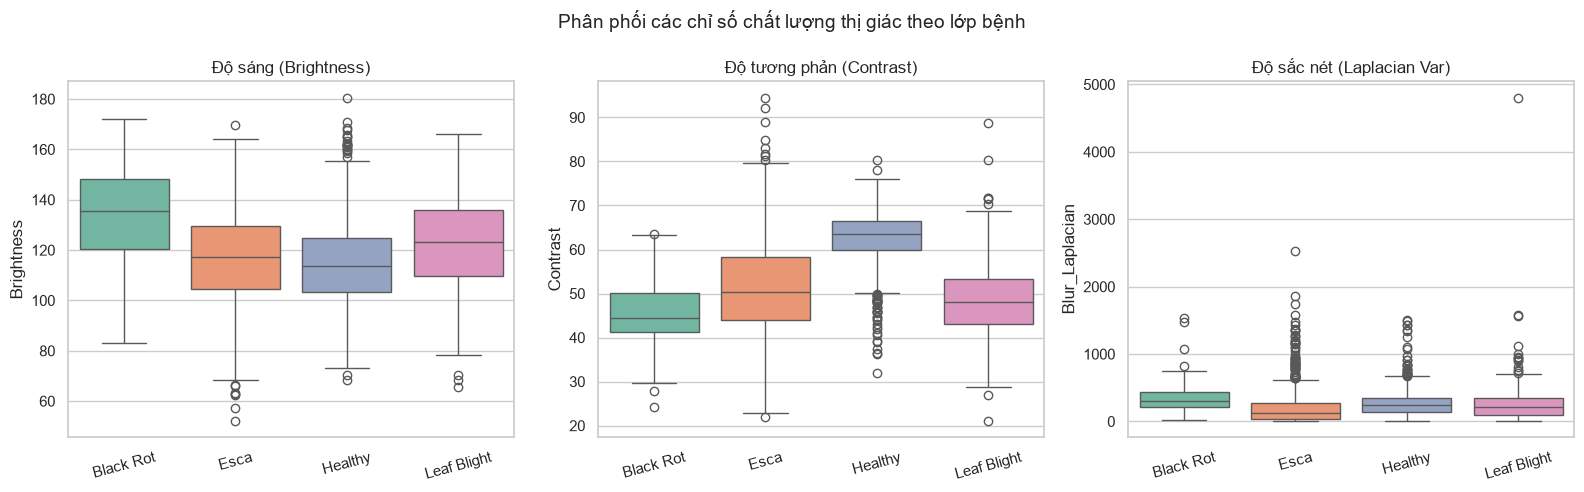

In [8]:
# Biểu đồ phân phối Độ sáng, Độ tương phản và Độ sắc nét theo từng loại bệnh
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = [("Brightness", "Độ sáng (Brightness)"), ("Contrast", "Độ tương phản (Contrast)"), ("Blur_Laplacian", "Độ sắc nét (Laplacian Var)")]

for ax, (col, title) in zip(axes, metrics):
    sns.boxplot(data=df_task1, x="Disease_Type", y=col, hue="Disease_Type", ax=ax, palette="Set2", legend=False)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Phân phối các chỉ số chất lượng thị giác theo lớp bệnh", fontsize=14)
plt.tight_layout()
plt.show()

- Độ sáng và độ tương phản **khác nhau rõ giữa các lớp**: Black Rot sáng hơn (median ≈135 so với ≈114–123) và tương phản thấp hơn (≈45 so với ≈63 của Healthy). Healthy có độ tương phản cao nhất.
- Điều này cho thấy ảnh của từng lớp có thể được chụp ở điều kiện hoặc đợt chụp khác nhau. Mô hình CNN có thể học "đường tắt" theo độ sáng và màu thay vì triệu chứng bệnh. Nên dùng augmentation độ sáng/tương phản và kiểm tra bằng Grad-CAM.
- Mục 5.1 so sánh độ sáng thật của ảnh với các cột điều kiện chụp trong metadata.

### 5.1. Metadata điều kiện chụp có khớp với ảnh thật không?

Nếu cột `Lighting`, `Time_of_Capture`, `Weather` thật sự mô tả điều kiện lúc chụp thì độ sáng của ảnh phải khác nhau theo các nhóm này (ví dụ ảnh buổi sáng và buổi chiều, trời nhiều mây và nắng). Dùng kiểm định Kruskal–Wallis so độ sáng (`Brightness`) theo từng thuộc tính. `Epsilon2` là cỡ ảnh hưởng (0 = không khác biệt, gần 1 = khác biệt rất lớn). `Disease_Type` được đưa vào làm mốc so sánh.

#### 📝 Giải thích cell: metadata điều kiện chụp có khớp ảnh thật không?
**Giả thuyết:** nếu `Lighting`, `Time_of_Capture`, `Weather` mô tả đúng lúc chụp thì độ sáng thật của ảnh phải khác nhau giữa các nhóm.

**Từng bước:**
1. Với mỗi thuộc tính, chia `Brightness` thành các nhóm theo giá trị của thuộc tính.
2. Chạy **Kruskal–Wallis** (phiên bản không tham số của ANOVA, không giả định phân phối chuẩn) để hỏi "các nhóm có cùng phân phối độ sáng không?". Kết quả là thống kê `H` và `p_value`.
3. Tính **epsilon² (ε²)** = (H − k + 1)/(n − k), là **cỡ ảnh hưởng**: 0 = không khác biệt, gần 1 = rất khác biệt. Cần cả p-value và ε²: p nhỏ chỉ nói "có khác", ε² nói "khác nhiều hay ít".
4. Với thuộc tính có ≤ 4 nhóm, in thêm trung vị độ sáng từng nhóm.
5. Thêm `Disease_Type` làm **mốc so sánh**: nếu ε² của thời tiết/ánh sáng nhỏ hơn nhiều so với của loại bệnh thì metadata môi trường gần như không phản ánh ảnh.

**Cách đọc:** ε² của các cột môi trường ≈ 0 và p lớn → các cột đó **không** liên quan đến nội dung ảnh, nên cần nêu rõ hạn chế này ở Bài 2.

In [9]:
from scipy.stats import kruskal

rows = []
for col in [
    "Environmental_Conditions.Lighting",
    "Environmental_Conditions.Time_of_Capture",
    "Environmental_Conditions.Weather",
    "Location.Vineyard",
    "Disease_Type",
]:
    groups = [grp["Brightness"].values for _, grp in df_task1.groupby(col)]
    k, n = len(groups), len(df_task1)
    h_stat, p_value = kruskal(*groups)
    eps2 = max(0.0, (h_stat - k + 1) / (n - k))     # cỡ ảnh hưởng epsilon-squared
    row = dict(Thuoc_tinh=col, So_nhom=k, H=round(h_stat, 2), p_value=p_value, Epsilon2=round(eps2, 4))
    if k <= 4:
        row["Median_Brightness"] = df_task1.groupby(col)["Brightness"].median().round(1).to_dict()
    rows.append(row)

display(pd.DataFrame(rows))

,Thuoc_tinh,So_nhom,H,p_value,Epsilon2,Median_Brightness
0,Environmental_Conditions.Lighting,3,0.03,9.861542e-01,0.0000,"{'Natural sunlight': 116.6, 'Overcast': 116.8,..."
1,Environmental_Conditions.Time_of_Capture,3,0.65,7.243093e-01,0.0000,"{'Afternoon': 116.6, 'Evening': 117.1, 'Mornin..."
2,Environmental_Conditions.Weather,3,3.16,2.058186e-01,0.0005,"{'Clear': 115.6, 'Humid': 117.7, 'Windy': 116.4}"
3,Location.Vineyard,28,21.68,7.532133e-01,0.0000,NaN
4,Disease_Type,4,137.40,1.375597e-29,0.0559,"{'Black Rot': 135.3, 'Esca': 117.4, 'Healthy':..."


### 6. Kiểm tra ảnh gần trùng (perceptual hash)

MD5 chỉ bắt được ảnh giống hệt từng byte. Cell này dùng **dHash** (băm cảm nhận 64 bit) để tìm ảnh **gần giống nhau** (ảnh nén lại, resize, lật ngang/dọc, xoay 180°) trong tập ảnh duy nhất, rồi gom thành các nhóm gần trùng. Bước này chạy **trước** khi chia tập để kết quả dùng làm sạch dữ liệu ở mục 6.1.

- `NEAR_DUP_THRESHOLD` là khoảng cách Hamming tối đa để coi là gần trùng (mặc định 3 trên 64 bit).
- dHash 8×8 khá thô và ảnh lá nho có bố cục tương tự nhau nên **có thể có cặp báo nhầm**. Vì vậy cell hiển thị ví dụ để xem bằng mắt trước khi kết luận.
- Cell này chỉ **phát hiện** các cặp ứng viên. Việc kiểm chứng và loại bỏ nằm ở mục 6.1.

#### 📝 Giải thích cell: tìm ảnh gần trùng bằng dHash
**Vấn đề:** MD5 chỉ bắt ảnh giống từng byte. Ảnh bị nén lại, đổi kích thước, lật... có MD5 khác nhưng nhìn gần như giống.

**dHash (difference hash) hoạt động thế nào:**
1. Thu nhỏ ảnh xám còn **9×8** điểm.
2. So từng điểm với điểm bên phải: sáng hơn → bit 1, ngược lại → bit 0. Ra **64 bit**.
3. Hai ảnh gần giống có hash khác nhau rất ít bit. Số bit khác nhau gọi là **khoảng cách Hamming**.

**Từng bước trong cell:**
1. `dhash_variants`: tính hash cho 4 biến thể (gốc, lật ngang, lật dọc, xoay 180°) để bắt cả ảnh bị lật.
2. `popcount64`: đếm số bit 1 (= khoảng cách Hamming sau phép XOR).
3. Vòng lặp so từng ảnh `i` với các ảnh sau nó, lấy **khoảng cách nhỏ nhất** qua 4 biến thể, ghi nhận cặp có `d ≤ NEAR_DUP_THRESHOLD` (mặc định 3).
4. In **phân bố khoảng cách tới ảnh gần nhất** (để chọn ngưỡng hợp lý: nếu có cụm dồn ở 0–3 rồi vắng thì ngưỡng tốt).
5. **Union-find** (`group_by_pairs`) gom các cặp thành nhóm, ảnh cùng nhóm có cùng mã.
6. Đếm: số cặp, số ảnh liên quan, số nhóm gần trùng và số cặp **khác lớp** (nghi nhãn sai).
7. Vẽ 6 cặp gần nhất để **xem bằng mắt**.

**Cách đọc & hạn chế:** dHash 8×8 khá thô, ảnh lá nho bố cục giống nhau có thể báo nhầm. Vì vậy phải xem hình trước khi kết luận. Số cặp khác lớp càng cao càng cần kiểm chứng kỹ ở mục 6.1 trước khi loại.

Phân bố khoảng cách tới ảnh gần nhất (số ảnh):


,So_anh
0,280
1,64
2,16
3,2
8,1
10,2044



Ngưỡng gần trùng            : khoảng cách Hamming <= 3
Số cặp ảnh gần trùng         : 181
Số ảnh nằm trong các cặp     : 362
Số nhóm gần trùng (chưa kiểm chứng): 181
Số cặp khác lớp              : 180   <- nghi mâu thuẫn nhãn, kiểm chứng ở mục 6.1


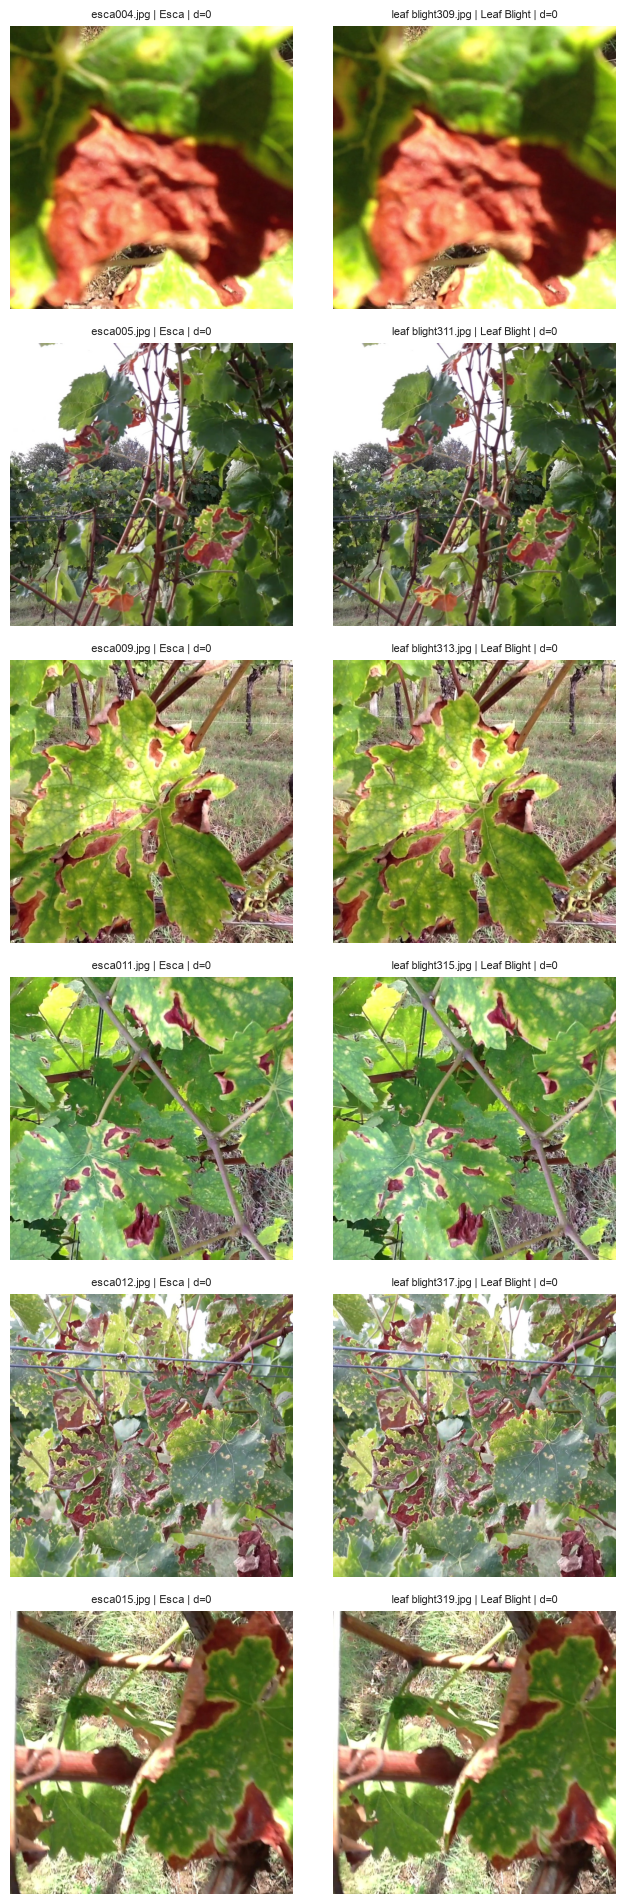

In [10]:
NEAR_DUP_THRESHOLD = 3

def dhash_variants(rel_path, hash_size=8):
    """dHash của ảnh gốc, lật ngang, lật dọc và xoay 180 độ (mỗi cái 64 bit)."""
    img_bytes = np.fromfile(str(DATASET_DIR / rel_path), dtype=np.uint8)
    gray = cv2.imdecode(img_bytes, cv2.IMREAD_GRAYSCALE)
    small = cv2.resize(gray, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    out = []
    for v in (small, small[:, ::-1], small[::-1, :], small[::-1, ::-1]):
        bits = (v[:, 1:] > v[:, :-1]).flatten()
        out.append(int("".join("1" if b else "0" for b in bits), 2))
    return out

def popcount64(x):
    x = np.ascontiguousarray(x, dtype=np.uint64)
    return np.unpackbits(x.view(np.uint8)).reshape(-1, 64).sum(axis=1)

def group_by_pairs(n_items, pair_list):
    """Union-find: trả về mã nhóm của từng ảnh (ảnh cùng nhóm có cùng mã)."""
    parent = list(range(n_items))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for i, j, *_ in pair_list:
        ri, rj = find(i), find(j)
        if ri != rj:
            parent[rj] = ri
    return [find(i) for i in range(n_items)]

hash_arr = np.array([dhash_variants(p) for p in df_task1["Image_Path"]], dtype=np.uint64)   # (n, 4)
n = len(hash_arr)

nn_dist = np.full(n, 64)       # khoảng cách tới ảnh gần nhất của mỗi ảnh
pairs = []
for i in range(n - 1):
    x = hash_arr[i + 1:] ^ hash_arr[i, 0]                       # so ảnh i với 4 biến thể của các ảnh sau
    d = popcount64(x.reshape(-1)).reshape(-1, 4).min(axis=1)
    nn_dist[i] = min(nn_dist[i], d.min())
    nn_dist[i + 1:] = np.minimum(nn_dist[i + 1:], d)
    for j in np.where(d <= NEAR_DUP_THRESHOLD)[0]:
        pairs.append((i, i + 1 + int(j), int(d[j])))

print("Phân bố khoảng cách tới ảnh gần nhất (số ảnh):")
display(pd.Series(nn_dist).clip(upper=10).value_counts().sort_index().rename("So_anh").to_frame())

class_arr = df_task1["Disease_Type"].values
cross_class = [(i, j, d) for i, j, d in pairs if class_arr[i] != class_arr[j]]
n_in_pairs = len({a for p in pairs for a in p[:2]})
raw_groups = pd.Series(group_by_pairs(n, pairs)).value_counts()

print(f"\nNgưỡng gần trùng            : khoảng cách Hamming <= {NEAR_DUP_THRESHOLD}")
print(f"Số cặp ảnh gần trùng         : {len(pairs)}")
print(f"Số ảnh nằm trong các cặp     : {n_in_pairs}")
print(f"Số nhóm gần trùng (chưa kiểm chứng): {int((raw_groups > 1).sum())}")
print(f"Số cặp khác lớp              : {len(cross_class)}   <- nghi mâu thuẫn nhãn, kiểm chứng ở mục 6.1")

# Xem bằng mắt một số cặp gần trùng nhất
show = sorted(pairs, key=lambda t: t[2])[:6]
if show:
    fig, axes = plt.subplots(len(show), 2, figsize=(7, 3.2 * len(show)))
    axes = np.atleast_2d(axes)
    for r, (i, j, d) in enumerate(show):
        for c, idx in enumerate((i, j)):
            row = df_task1.iloc[idx]
            img = cv2.imdecode(np.fromfile(str(DATASET_DIR / row["Image_Path"]), dtype=np.uint8), cv2.IMREAD_COLOR)
            axes[r, c].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[r, c].axis("off")
            axes[r, c].set_title(f"{row['Image_Name']} | {row['Disease_Type']} | d={d}", fontsize=8)
    plt.tight_layout(); plt.show()


- dHash (khoảng cách Hamming ≤ 3) cho **181 cặp** gần trùng, gồm 362 ảnh và 181 nhóm, nghĩa là mỗi nhóm đúng 2 ảnh, không có chuỗi nối dài. Trong đó **180/181 cặp nằm ở hai lớp bệnh khác nhau**: ảnh gần trùng ở đây gần như luôn là một bức ảnh bị đặt vào hai thư mục bệnh, không phải trùng ngẫu nhiên trong cùng lớp.
- Phân bố khoảng cách có khoảng trống rõ: 280 ảnh ở d=0, 64 ở d=1, 16 ở d=2, 2 ở d=3 (cộng lại đúng 362 ảnh), chỉ 1 ảnh ở d=8, còn lại (2.044 ảnh) d ≥ 10. Ngưỡng 3 nằm trong khoảng trống nên không nhạy.
- Xem bằng mắt 6 cặp gần nhất: hai ảnh là **cùng một bức ảnh** (khác nhau chút ít do nén lại), ví dụ `esca004.jpg` và `leaf blight309.jpg`, `esca005.jpg` và `leaf blight311.jpg`. Các cặp nhìn thấy đều là một ảnh Esca ghép với một ảnh Leaf Blight.
- Mục 6.1 kiểm chứng lại bằng so sánh điểm ảnh và quyết định xử lý.

### 6.1. Kiểm chứng và xử lý ảnh gần trùng

dHash 8×8 khá thô nên cell này kiểm chứng lại từng cặp bằng cách **so trực tiếp điểm ảnh** (ảnh xám 32×32, tính MSE, thử cả 4 biến thể lật/xoay). Chỉ các cặp có MSE ≤ `NEAR_CONFIRM_MSE` mới được coi là cùng một ảnh. Sau đó gom nhóm lại từ các cặp đã xác nhận và xử lý:

| Nhóm gần trùng | Cách xử lý | Lý do |
|---|---|---|
| Cùng lớp | Giữ 1 ảnh nét nhất (`Blur_Laplacian` cao nhất) | Các bản còn lại không thêm thông tin, và để chúng lại sẽ gây rò rỉ train/test |
| Khác lớp | **Loại cả nhóm**, kể cả các bản sao MD5 của chúng | Không xác minh được nhãn đúng. Dataset gán đơn nhãn nên cũng không thể coi đó là lá đa bệnh |

Việc loại cả nhóm khác lớp áp dụng cho cả bộ `task2_env_full.csv` (các bản sao MD5 của ảnh bị loại cũng bị bỏ) để hai bài dùng cùng một tập ảnh hợp lệ.

#### 📝 Giải thích cell: kiểm chứng và xử lý ảnh gần trùng
**Từng bước:**
1. **`NEAR_CONFIRM_MSE`**: ngưỡng MSE (thang xám 0–255) để xác nhận hai ảnh là cùng một ảnh. Ảnh nén lại hay lật chỉ lệch rất ít điểm ảnh nên MSE nhỏ; hai lá khác nhau thì MSE lớn.
2. **Tính MSE cho từng cặp** từ mục 6, so ảnh `i` với 4 biến thể của ảnh `j` và lấy giá trị nhỏ nhất (giống cách dHash đã so).
3. **Histogram MSE + 4 cặp "biên"** (khác lớp, MSE sát ngưỡng): dùng để chọn ngưỡng hợp lý. Nếu histogram có khoảng trống giữa hai cụm thì đặt ngưỡng vào khoảng trống đó. Nếu các cặp biên nhìn rõ là hai ảnh khác nhau thì **giảm** ngưỡng.
4. **`pairs_ok`**: các cặp được xác nhận, rồi gom lại bằng union-find thành `Near_Group_Id` (mã nhóm cuối cùng).
5. **Loại nhóm khác lớp**: nhóm nào có hơn 1 lớp thì bỏ toàn bộ ảnh trong nhóm, và bỏ luôn mọi bản ghi trong `df_consistent` có cùng MD5. In **bảng tác động theo lớp** (`Truoc`, `Bi_xoa`, `Con_lai`, `Ty_le_mat`): nếu lớp nào (đặc biệt Black Rot) mất quá nhiều thì xem lại ngưỡng hoặc từng cặp.
6. **Nhóm cùng lớp**: giữ 1 ảnh có `Blur_Laplacian` cao nhất, bỏ các ảnh còn lại.
7. **`assert`**: sau bước này mỗi `Near_Group_Id` và mỗi MD5 chỉ còn đúng 1 ảnh. `near_stats` lưu số liệu để ghi vào file cấu hình ở mục 9.

**Lưu ý:** cell này phải chạy **ngay sau** cell mục 6 (dùng chung `pairs` và `class_arr`). Chạy lại cell này mà không chạy lại từ mục 3 sẽ sai vì `df_task1` và `df_consistent` đã bị thay đổi.

Số cặp dHash đề xuất      : 181
  - được xác nhận (MSE <= 100) : 180
  - bị loại (báo nhầm)     : 1
Số cặp khác lớp được xác nhận: 180


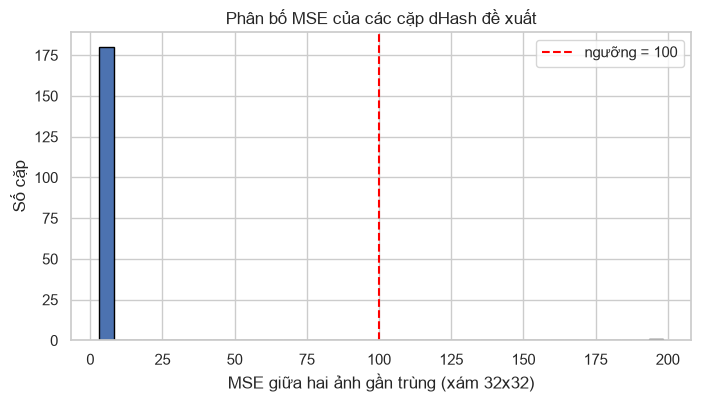

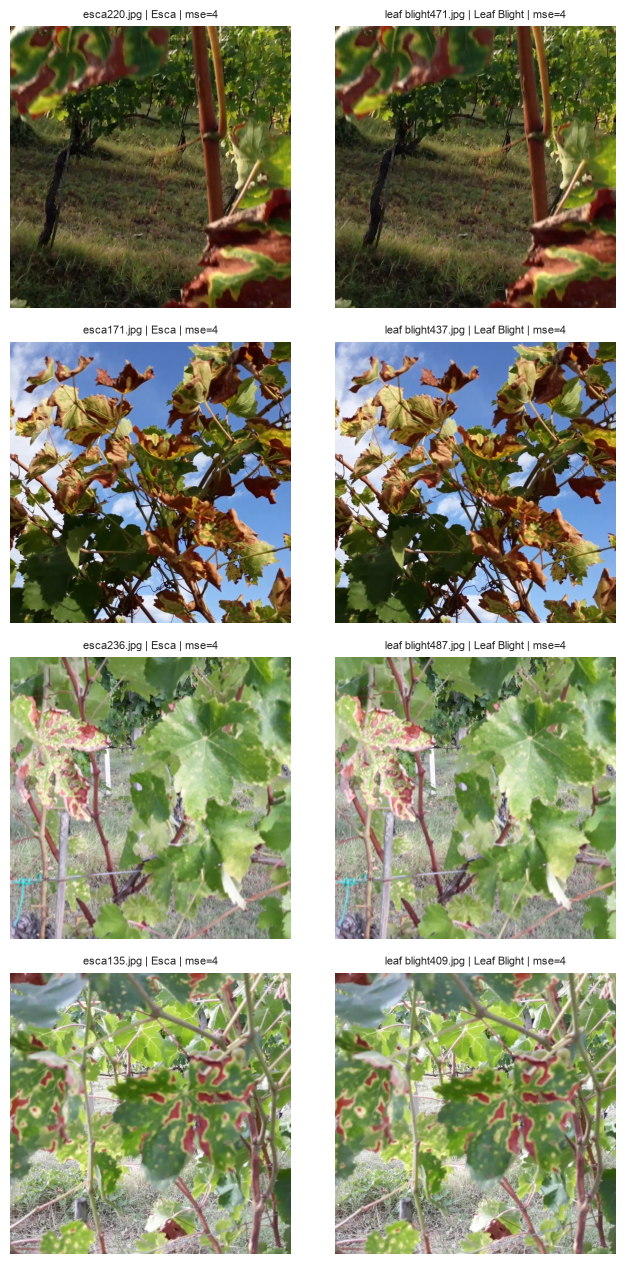


Nhóm gần trùng khác lớp bị loại: 180 nhóm, 360 ảnh duy nhất, 554 bản ghi (gồm cả bản sao MD5)


,Truoc,Bi_xoa,Con_lai,Ty_le_mat (%)
Disease_Type,,,,
Healthy,1093,1,1092,0.1
Esca,886,179,707,20.2
Leaf Blight,331,179,152,54.1
Black Rot,97,1,96,1.0


Gộp ảnh gần trùng cùng lớp      : bỏ 0 ảnh
Ảnh duy nhất cuối cùng (Bài 1)  : 2047  (trước mục 6.1: 2407)
Bản ghi nhất quán cuối (Bài 2 Full): 2904


,So_anh,Ty_le (%)
Disease_Type,,
Healthy,1092,53.35
Esca,707,34.54
Leaf Blight,152,7.43
Black Rot,96,4.69


In [11]:
# 6.1 Kiểm chứng bằng so sánh điểm ảnh, rồi xử lý nhóm gần trùng
NEAR_CONFIRM_MSE = 100   # MSE tối đa (ảnh xám 32x32, thang 0-255) để xác nhận hai ảnh là cùng một ảnh

paths = df_task1["Image_Path"].tolist()
_small_cache = {}
def get_small(idx, size=32):
    if idx not in _small_cache:
        g = cv2.imdecode(np.fromfile(str(DATASET_DIR / paths[idx]), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
        _small_cache[idx] = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)
    return _small_cache[idx]

rows = []
for i, j, d in pairs:
    A, B = get_small(i), get_small(j)
    # so với 4 biến thể của ảnh j (gốc, lật ngang, lật dọc, xoay 180), giống cách dHash đã so
    mse = min(float(np.mean((A - v) ** 2)) for v in (B, B[:, ::-1], B[::-1, :], B[::-1, ::-1]))
    rows.append(dict(i=i, j=j, dhash=d, mse=mse,
                     img_i=df_task1.iloc[i]["Image_Name"], cls_i=class_arr[i],
                     img_j=df_task1.iloc[j]["Image_Name"], cls_j=class_arr[j]))
pair_df = pd.DataFrame(rows, columns=["i", "j", "dhash", "mse", "img_i", "cls_i", "img_j", "cls_j"])
pair_df["cross_class"] = pair_df["cls_i"] != pair_df["cls_j"]
confirmed = pair_df["mse"] <= NEAR_CONFIRM_MSE

print(f"Số cặp dHash đề xuất      : {len(pair_df)}")
print(f"  - được xác nhận (MSE <= {NEAR_CONFIRM_MSE}) : {int(confirmed.sum())}")
print(f"  - bị loại (báo nhầm)     : {int((~confirmed).sum())}")
print(f"Số cặp khác lớp được xác nhận: {int((confirmed & pair_df['cross_class']).sum())}")

if len(pair_df):
    plt.figure(figsize=(8, 4))
    plt.hist(pair_df["mse"], bins=40, edgecolor="black")
    plt.axvline(NEAR_CONFIRM_MSE, color="red", linestyle="--", label=f"ngưỡng = {NEAR_CONFIRM_MSE}")
    plt.xlabel("MSE giữa hai ảnh gần trùng (xám 32x32)"); plt.ylabel("Số cặp"); plt.legend()
    plt.title("Phân bố MSE của các cặp dHash đề xuất"); plt.show()

# Các cặp khác lớp có MSE sát ngưỡng: xem bằng mắt để chọn ngưỡng
border = (pair_df[pair_df["cross_class"]]
          .assign(gap=lambda d: (d["mse"] - NEAR_CONFIRM_MSE).abs())
          .sort_values("gap").head(4))
if len(border):
    fig, axes = plt.subplots(len(border), 2, figsize=(7, 3.2 * len(border)))
    axes = np.atleast_2d(axes)
    for r, row in enumerate(border.itertuples()):
        for c, (idx, name, cls) in enumerate(((row.i, row.img_i, row.cls_i), (row.j, row.img_j, row.cls_j))):
            img = cv2.imdecode(np.fromfile(str(DATASET_DIR / paths[idx]), dtype=np.uint8), cv2.IMREAD_COLOR)
            axes[r, c].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[r, c].axis("off")
            axes[r, c].set_title(f"{name} | {cls} | mse={row.mse:.0f}", fontsize=8)
    plt.tight_layout(); plt.show()

# Gom nhóm lại chỉ từ các cặp đã xác nhận
pairs_ok = [(int(r.i), int(r.j), int(r.dhash)) for r in pair_df[confirmed].itertuples()]
df_task1["Near_Group_Id"] = group_by_pairs(len(df_task1), pairs_ok)
n_unique_before = len(df_task1)

# (a) Nhóm gần trùng có >1 lớp: không xác minh được nhãn -> loại cả nhóm (và mọi bản sao MD5 của chúng)
nclass = df_task1.groupby("Near_Group_Id")["Disease_Type"].nunique()
bad_groups = nclass[nclass > 1].index
df_near_conflict = df_task1[df_task1["Near_Group_Id"].isin(bad_groups)].copy()
bad_md5 = set(df_near_conflict["MD5"])

df_near_conflict_full = df_consistent[df_consistent["MD5"].isin(bad_md5)].copy()
df_near_conflict_full["Reason"] = "near_dup_label_conflict"

impact = pd.concat([
    df_task1["Disease_Type"].value_counts().rename("Truoc"),
    df_near_conflict["Disease_Type"].value_counts().rename("Bi_xoa"),
], axis=1).fillna(0).astype(int)
impact["Con_lai"] = impact["Truoc"] - impact["Bi_xoa"]
impact["Ty_le_mat (%)"] = (impact["Bi_xoa"] / impact["Truoc"] * 100).round(1)
print(f"\nNhóm gần trùng khác lớp bị loại: {len(bad_groups)} nhóm, {len(df_near_conflict)} ảnh duy nhất, "
      f"{len(df_near_conflict_full)} bản ghi (gồm cả bản sao MD5)")
display(impact)

df_consistent = df_consistent[~df_consistent["MD5"].isin(bad_md5)].reset_index(drop=True)
df_task1 = df_task1[~df_task1["MD5"].isin(bad_md5)].reset_index(drop=True)

# (b) Nhóm gần trùng cùng lớp: mỗi nhóm giữ 1 ảnh nét nhất
n_before_sharp = len(df_task1)
df_task1 = (df_task1.sort_values("Blur_Laplacian", ascending=False)
            .drop_duplicates("Near_Group_Id", keep="first")
            .sort_values(["Disease_Type", "Image_Number"])
            .reset_index(drop=True))
assert df_task1["Near_Group_Id"].is_unique and df_task1["MD5"].is_unique

near_stats = {
    "pairs_dhash": len(pair_df),
    "pairs_confirmed": int(confirmed.sum()),
    "conflict_groups": int(len(bad_groups)),
    "same_class_dropped": int(n_before_sharp - len(df_task1)),
}
print(f"Gộp ảnh gần trùng cùng lớp      : bỏ {near_stats['same_class_dropped']} ảnh")
print(f"Ảnh duy nhất cuối cùng (Bài 1)  : {len(df_task1)}  (trước mục 6.1: {n_unique_before})")
print(f"Bản ghi nhất quán cuối (Bài 2 Full): {len(df_consistent)}")
display(df_task1["Disease_Type"].value_counts().rename("So_anh").to_frame()
        .assign(**{"Ty_le (%)": lambda d: (d["So_anh"] / d["So_anh"].sum() * 100).round(2)}))


**Kết quả kiểm chứng và xử lý (mục 6.1)**

- **Kiểm chứng:** 181 cặp dHash, trong đó 180 cặp được xác nhận (MSE ≤ 100) và 1 cặp bị loại vì báo nhầm. Cặp bị loại là cặp cùng lớp (suy ra từ việc cả 180 cặp khác lớp đều được xác nhận). Histogram MSE tách thành hai cụm rõ ràng: 180 cặp có MSE chỉ vài đơn vị (nằm sát 0) và 1 cặp có MSE khoảng 200. Ngưỡng `NEAR_CONFIRM_MSE = 100` nằm giữa khoảng trống nên kết quả **không phụ thuộc vào việc chọn ngưỡng**.
- **Cặp biên:** 4 cặp khác lớp sát ngưỡng nhất đều có MSE ≈ 4 (ví dụ `esca220.jpg` và `leaf blight471.jpg`). Nhìn bằng mắt vẫn là cùng một ảnh, nên không có cặp nào mơ hồ.
- **Nhóm khác lớp bị loại:** 180 nhóm, tương ứng 360 ảnh duy nhất và 554 bản ghi (gồm cả các bản sao MD5). Theo lớp: Esca mất 179 ảnh (20,2%), Leaf Blight mất 179 ảnh (54,1%), Healthy mất 1, Black Rot mất 1. Suy ra gần như toàn bộ là **179 cặp Esca–Leaf Blight** và 1 cặp Healthy–Black Rot.
- **Nhóm cùng lớp:** không có ảnh nào bị gộp (0 ảnh).
- **Kết quả cuối:** **2.047 ảnh duy nhất** (từ 2.407 trước mục 6.1) cho Bài 1, và **2.904 bản ghi** nhất quán (từ 3.458) cho Bài 2 bản Full. Phân bố lớp mới: Healthy 53,35%, Esca 34,54%, Leaf Blight 7,43%, Black Rot 4,69%.

**Quan sát về nguyên nhân (giả thuyết, chưa kiểm chứng):** các cặp ghép theo thứ tự tăng dần, ví dụ `esca004` với `leaf blight309`, `esca005` với `leaf blight311`, `esca009` với `leaf blight313`, ..., `esca236` với `leaf blight487`. Điều này gợi ý một dải ảnh trong thư mục Leaf Blight có thể là bản sao của ảnh Esca (copy hàng loạt), chứ không phải gán nhầm ngẫu nhiên. Hiện chưa biết lớp nào mới là nhãn đúng, nên theo nguyên tắc đã chọn thì loại cả hai. Nếu sau này xác minh được (kiểm tra dải số thứ tự, tra nguồn dataset hoặc hỏi chuyên gia) thì có thể khôi phục tối đa 179 ảnh.

**Hệ quả cần nhớ**
- Leaf Blight chỉ còn 152 ảnh duy nhất và Black Rot 96 ảnh, nên mất cân bằng lớp nặng hơn trước (Healthy hơn 53%).
- Các cặp khó phân biệt nhất giữa Esca và Leaf Blight đã bị loại khỏi dữ liệu, nên điểm của hai lớp này trên tập sạch có thể **lạc quan hơn thực tế**. Cần nêu trong báo cáo.

### 7. Chia tập dữ liệu Train / Val / Test (70% / 15% / 15%) & Tính Class Weights
Thực hiện chia phân tầng (`Stratified Split`) trên tập ảnh độc nhất (`df_task1`), đảm bảo:
1. Tỷ lệ các lớp bệnh đồng đều giữa 3 tập Train, Validation và Test.
2. Không có mã MD5 hay nhóm gần trùng (`Near_Group_Id`) nào xuất hiện ở cả 2 tập (Zero Data Leakage).

#### 📝 Giải thích cell: chia tập, 5 fold, class weight
**Mục đích:** chia dữ liệu để huấn luyện/đánh giá công bằng và xử lý mất cân bằng lớp.

**Từng bước:**
1. **Chia 70/15/15 có phân tầng (`stratify`)**: lần 1 tách 30% làm `temp`, lần 2 chia đôi `temp` thành val và test. Phân tầng giữ tỷ lệ các lớp gần như bằng nhau ở cả 3 tập.
2. **Gán cột `Split`** (`train`/`val`/`test`).
3. **`assert` kiểm tra không rò rỉ:** không MD5 và không `Near_Group_Id` nào nằm ở 2 tập. Nếu vi phạm, cell báo lỗi và dừng.
4. **Bảng thống kê** số lượng và % từng lớp mỗi tập.
5. **Class weight `balanced`:** `w_c = n / (số_lớp × n_c)`. Lớp ít mẫu có trọng số lớn, giúp hàm loss chú ý hơn tới lớp hiếm. Chỉ tính trên **tập train** (không nhìn val/test).
6. **5 fold phân tầng (`StratifiedKFold`)** → cột `Fold` 0–4. Black Rot chỉ có 14–15 ảnh ở val/test nên một lần chia rất nhiễu. Cross-validation cho kết quả ổn định hơn (báo cáo trung bình ± độ lệch chuẩn).
7. **Trọng số căn bậc hai:** `√w` giảm mức bù để tránh mô hình quá nghiêng về lớp hiếm.

**Quan trọng:** `Split` và `Fold` là hai cách chia **độc lập**. Đừng dùng val/test của `Split` rồi lại dùng `Fold` cho cùng một lần đánh giá. Chọn **một** (hoặc dùng `Fold` cho CV và giữ `test` làm kiểm tra cuối).

**Lưu ý:** phần chia tập chạy **sau** mục 6 và 6.1, nên `df_task1` đã được khử trùng cả theo MD5 lẫn theo nhóm gần trùng (mỗi `Near_Group_Id` chỉ còn 1 ảnh). Vì vậy chia ngẫu nhiên phân tầng là đủ, không cần `StratifiedGroupKFold`.

In [12]:
train_idx, temp_idx = train_test_split(
    df_task1.index,
    test_size=0.30,
    stratify=df_task1["Disease_Type"],
    random_state=RANDOM_STATE
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=df_task1.loc[temp_idx, "Disease_Type"],
    random_state=RANDOM_STATE
)

df_task1["Split"] = "train"
df_task1.loc[val_idx, "Split"] = "val"
df_task1.loc[test_idx, "Split"] = "test"

# Kiểm chứng không rò rỉ ảnh trùng (MD5) và ảnh gần trùng (Near_Group_Id) giữa các tập
def _ids(col, split):
    return set(df_task1.loc[df_task1["Split"] == split, col])

for col in ["MD5", "Near_Group_Id"]:
    tr, va, te = _ids(col, "train"), _ids(col, "val"), _ids(col, "test")
    assert not (tr & va) and not (tr & te) and not (va & te), f"Rò rỉ giữa các tập theo {col}"
n_cross_split_groups = int((df_task1.groupby("Near_Group_Id")["Split"].nunique() > 1).sum())
print("Kiểm tra Data Leakage: 0 ảnh trùng (MD5) và 0 nhóm gần trùng nằm ở 2 tập khác nhau!")

# Thống kê số lượng và tỷ lệ phần trăm từng tập
split_counts = pd.crosstab(df_task1["Split"], df_task1["Disease_Type"]).loc[["train", "val", "test"]]
split_pct = (split_counts.div(split_counts.sum(axis=1), axis=0) * 100).round(2)
split_summary = pd.concat([split_counts, split_pct], axis=1, keys=["So_luong", "Ty_le (%)"])
display(split_summary)

# Tính Class Weights trên tập Train đã khử trùng
y_train = df_task1.loc[df_task1["Split"] == "train", "Disease_Type"]
classes = np.sort(y_train.unique())
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights_dict = {c: round(float(w), 4) for c, w in zip(classes, weights)}
print("Class Weights trên tập Train (Unique):", class_weights_dict)

# Gán thêm 5 fold phân tầng để dùng cross-validation
# (lớp Black Rot chỉ có ~97 ảnh duy nhất nên một lần chia val/test cho kết quả rất nhiễu)
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
df_task1["Fold"] = -1
for fold, (_, te_pos) in enumerate(skf.split(df_task1, df_task1["Disease_Type"])):
    df_task1.loc[df_task1.index[te_pos], "Fold"] = fold
print("\nSố ảnh mỗi lớp trong từng fold:")
display(pd.crosstab(df_task1["Fold"], df_task1["Disease_Type"]))

# Trọng số căn bậc hai: giảm mức bù cho lớp ít mẫu (trọng số 'balanced' của Black Rot khá lớn)
class_weights_sqrt = {c: round(float(np.sqrt(w)), 4) for c, w in zip(classes, weights)}
print("Class Weights căn bậc hai (Train):", class_weights_sqrt)

Kiểm tra Data Leakage: 0 ảnh trùng (MD5) và 0 nhóm gần trùng nằm ở 2 tập khác nhau!


So_luong                          Ty_le (%)                 \
Disease_Type Black Rot Esca Healthy Leaf Blight Black Rot   Esca Healthy   
Split                                                                      
train               67  495     764         106      4.68  34.57   53.35   
val                 14  106     164          23      4.56  34.53   53.42   
test                15  106     164          23      4.87  34.42   53.25   

                          
Disease_Type Leaf Blight  
Split                     
train               7.40  
val                 7.49  
test                7.47

Class Weights trên tập Train (Unique): {'Black Rot': 5.3433, 'Esca': 0.7232, 'Healthy': 0.4686, 'Leaf Blight': 3.3774}

Số ảnh mỗi lớp trong từng fold:


Disease_Type,Black Rot,Esca,Healthy,Leaf Blight
Fold,,,,
0,20,141,218,31
1,19,142,218,31
2,19,142,218,30
3,19,141,219,30
4,19,141,219,30


Class Weights căn bậc hai (Train): {'Black Rot': 2.3116, 'Esca': 0.8504, 'Healthy': 0.6845, 'Leaf Blight': 1.8378}


- Phân tầng giữ đúng tỷ lệ các lớp ở cả 3 tập. Số ảnh (Black Rot / Esca / Healthy / Leaf Blight): train 67 / 495 / 764 / 106, val 14 / 106 / 164 / 23, test 15 / 106 / 164 / 23. Không có MD5 hay `Near_Group_Id` nào nằm ở hai tập, kiểm tra `assert` đã qua.
- **Black Rot chỉ có 14–15 ảnh và Leaf Blight chỉ có 23 ảnh ở val/test**, nên chỉ số của hai lớp này rất nhiễu (sai 1 ảnh Black Rot lệch khoảng 7% recall, sai 1 ảnh Leaf Blight lệch khoảng 4%). Nên dùng cột `Fold` (5 fold phân tầng, mỗi fold có 19–20 ảnh Black Rot và 30–31 ảnh Leaf Blight) để cross-validation và báo cáo trung bình ± độ lệch chuẩn.
- Class weight (balanced): Black Rot **5,34**, Leaf Blight **3,38**, Esca 0,72, Healthy 0,47. Bản căn bậc hai (`class_weights_sqrt`): Black Rot 2,31, Leaf Blight 1,84, Esca 0,85, Healthy 0,68. Nên thử cả hai kèm augmentation cho hai lớp hiếm.

### 8. Trích xuất đặc trưng ảnh dạng bảng (Handcrafted Features cho Data Mining)
Để phục vụ các mô hình Khai phá dữ liệu và Học máy cổ điển (SVM, Random Forest, XGBoost, KNN) trong Bài toán 1, mỗi bức ảnh được chuẩn hóa về kích thước `256x256` và trích xuất **25 đặc trưng thị giác**:
- **9 đặc trưng Màu sắc (Không gian màu HSV)**: Mean, Std, Skewness của 3 kênh Hue, Saturation, Value.
- **12 đặc trưng Kết cấu bề mặt lá (GLCM - Gray-Level Co-occurrence Matrix)**: Mean và Std của Contrast, Dissimilarity, Homogeneity, Energy, Correlation, ASM.
- **4 đặc trưng Hình dạng (Hu Moments)**: 4 moment bất biến đầu tiên, tính trên mặt nạ nhị phân (Otsu) và biến đổi logarit. Không dùng Hu 5–7 vì khi tính trên ảnh xám chúng bão hòa ở ±12 (chỉ còn là nhiễu dấu).

#### 📝 Giải thích cell: trích 25 đặc trưng thủ công
**Mục đích:** biến mỗi ảnh thành một **vector 25 số** để dùng với mô hình cổ điển (SVM, RF, XGBoost, KNN).

**Từng bước:** (mỗi ảnh được resize 256×256 trước)
1. **Màu HSV, 9 đặc trưng:** đổi sang không gian HSV (Hue = sắc, Saturation = độ đậm, Value = độ sáng). Với mỗi kênh tính mean, std, skewness. HSV hợp hơn RGB vì tách riêng màu khỏi độ sáng, mà bệnh lá thường làm đổi màu (úa vàng, nâu).
2. **Kết cấu GLCM, 12 đặc trưng:** GLCM đếm các cặp điểm ảnh liền kề có mức xám nào cạnh nhau. Từ đó tính contrast, dissimilarity, homogeneity, energy, correlation, ASM. Ảnh xám được lượng tử hóa còn **64 mức** (`//4`) để ma trận bớt thưa, ổn định hơn. Tính ở 2 khoảng cách × 4 góc rồi lấy mean và std.
3. **Hình dạng Hu Moments, 4 đặc trưng:** nhị phân hóa bằng **Otsu** (tự chọn ngưỡng tách nền/lá), tính 4 moment bất biến đầu tiên, rồi lấy `-sign·log10|h|` để thu hẹp thang số.

**Vì sao chỉ lấy 4 Hu Moments đầu?** Moment 5–7 rất nhỏ nên phép log bão hòa ở ±12 và chỉ còn nhiễu dấu (đã gặp ở output cũ).

**Kết quả:** `df_task1_features` gồm cột định danh (`Sr_No`, `Image_Name`, `Split`, `Fold`, `Near_Group_Id`, `MD5`...) + 25 cột đặc trưng.

**Lưu ý:** cột `Near_Group_Id` có trong bảng này nên mục 6 và 6.1 phải chạy **trước** cell này (đúng thứ tự hiện tại).

In [13]:
try:
    from skimage.feature import graycomatrix, graycoprops
except ImportError:
    from skimage.feature.texture import greycomatrix as graycomatrix, greycoprops as graycoprops

def extract_handcrafted_features(rel_path, resize_dim=(256, 256)):
    full_path = DATASET_DIR / rel_path
    img_bytes = np.fromfile(str(full_path), dtype=np.uint8)
    img_bgr = cv2.imdecode(img_bytes, cv2.IMREAD_COLOR)
    img_bgr = cv2.resize(img_bgr, resize_dim, interpolation=cv2.INTER_AREA)

    # 1. Đặc trưng Màu sắc (HSV: Mean, Std, Skewness)
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    color_feats = []
    for i in range(3):
        ch = img_hsv[:, :, i].astype(np.float32)
        mean = float(np.mean(ch))
        std = float(np.std(ch))
        skew = float(np.mean(((ch - mean) / (std + 1e-6)) ** 3))
        color_feats.extend([mean, std, skew])

    # 2. Đặc trưng Kết cấu (GLCM trên ảnh mức xám)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    img_gray_q = (img_gray // 4).astype(np.uint8)      # lượng tử hóa còn 64 mức xám cho GLCM ổn định hơn
    glcm = graycomatrix(
        img_gray_q,
        distances=[1, 3],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=64,
        symmetric=True,
        normed=True
    )
    texture_feats = []
    glcm_props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    for prop in glcm_props:
        vals = graycoprops(glcm, prop)
        texture_feats.append(float(np.mean(vals)))
        texture_feats.append(float(np.std(vals)))

    # 3. Đặc trưng Hình dạng: Hu Moments trên mặt nạ nhị phân (Otsu), giữ 4 moment đầu
    _, mask = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    hu = cv2.HuMoments(cv2.moments(mask, binaryImage=True)).flatten()[:4]
    hu_feats = [float(-np.sign(h) * np.log10(np.abs(h) + 1e-12)) for h in hu]

    feat_names = (
        [f"HSV_{c}_{s}" for c in ["H", "S", "V"] for s in ["mean", "std", "skew"]]
        + [f"GLCM_{p}_{s}" for p in glcm_props for s in ["mean", "std"]]
        + [f"HuMoment_{i+1}" for i in range(4)]
    )
    return pd.Series(color_feats + texture_feats + hu_feats, index=feat_names)

print("Đang trích xuất 25 đặc trưng Màu sắc (HSV) + Kết cấu (GLCM) + Hình dạng (Hu Moments)...")
df_handcrafted = df_task1["Image_Path"].apply(extract_handcrafted_features)

df_task1_features = pd.concat([
    df_task1[["Sr_No", "Image_Name", "Image_Path", "Disease_Type", "Split", "Fold", "Near_Group_Id", "MD5"]],
    df_handcrafted
], axis=1)

print("Kích thước bảng đặc trưng Bài 1:", df_task1_features.shape)
display(df_task1_features.head())

Đang trích xuất 25 đặc trưng Màu sắc (HSV) + Kết cấu (GLCM) + Hình dạng (Hu Moments)...
Kích thước bảng đặc trưng Bài 1: (2047, 33)


,Sr_No,Image_Name,Image_Path,Disease_Type,Split,Fold,Near_Group_Id,MD5,HSV_H_mean,HSV_H_std,...,GLCM_energy_mean,GLCM_energy_std,GLCM_correlation_mean,GLCM_correlation_std,GLCM_ASM_mean,GLCM_ASM_std,HuMoment_1,HuMoment_2,HuMoment_3,HuMoment_4
0,1,black rot001.jpg,Black rot/black rot001.jpg,Black Rot,train,4,0,f9842245a80e11875f278315b091c333,29.641907,14.047880,...,0.063145,0.010404,0.873870,0.057530,0.004096,0.001345,0.343883,2.352575,3.366887,4.020259
1,9,black rot009.jpg,Black rot/black rot009.jpg,Black Rot,test,4,1,b277e84492c0e766574bef7a6c68e527,28.908401,9.446168,...,0.073959,0.010458,0.898834,0.052776,0.005579,0.001575,0.306413,3.065404,2.601726,3.043227
2,13,black rot013.jpg,Black rot/black rot013.jpg,Black Rot,test,3,2,50fdb56fbf6fa11840da3f92a7337278,30.951843,7.512039,...,0.057659,0.008699,0.842111,0.072645,0.003400,0.001025,0.622581,3.104047,4.132762,3.289796
3,25,black rot025.jpg,Black rot/black rot025.jpg,Black Rot,train,4,3,e956d299b80ec98c4cb26c0556da819f,29.760468,16.821621,...,0.047631,0.006590,0.845561,0.069731,0.002312,0.000641,0.550122,2.562137,3.546257,4.467809
4,33,black rot033.jpg,Black rot/black rot033.jpg,Black Rot,train,1,4,0624463b2944ea90674514e5e7c650f6,25.566849,10.778706,...,0.044394,0.006832,0.840940,0.068806,0.002018,0.000623,0.634131,3.534489,3.873799,4.400983


- Output cũ của bảng đặc trưng cho thấy **`HuMoment_5`, `HuMoment_6`, `HuMoment_7` luôn bằng ±12** (±11,99997...): các moment này nhỏ hơn 1e-12 khi tính trên ảnh xám nên phép biến đổi logarit bão hòa, chỉ còn dấu ngẫu nhiên. `HuMoment_3` và `HuMoment_4` cũng gần ngưỡng 12.
- Cell đã được sửa: Hu Moments tính trên **mặt nạ nhị phân (Otsu)** và chỉ giữ 4 moment đầu; GLCM lượng tử hóa còn 64 mức xám. Tổng còn **25 đặc trưng**. Chưa chạy lại trên dữ liệu thật, cell chẩn đoán bên dưới sẽ kiểm tra có đặc trưng nào còn hằng số hoặc bão hòa không.

#### 📝 Giải thích cell: chẩn đoán chất lượng đặc trưng
**Mục đích:** kiểm tra đặc trưng "xấu" trước khi đưa vào mô hình.

**Các kiểm tra:**
1. **Bảng `diag`:** độ lệch chuẩn, min, max của từng đặc trưng.
2. **Hằng số:** `Std < 1e-6` nghĩa là mọi ảnh cùng một giá trị, vô dụng.
3. **Bão hòa (chỉ Hu):** tỷ lệ ảnh có `|x| ≥ 11.99`; vượt 50% thì đặc trưng chỉ còn nhiễu.
4. **NaN:** đếm giá trị khuyết.

**Cách đọc:** mong đợi "Không có" cho cả hằng số và bão hòa, và NaN = 0. Nếu có đặc trưng bị liệt kê thì loại nó khỏi bộ đặc trưng. Cột `Ty_le_bao_hoa_Hu` chỉ có giá trị với 4 cột Hu, các cột khác hiện `NaN` là bình thường.

In [14]:
# Kiểm tra chất lượng đặc trưng: hằng số, bão hòa (chỉ áp dụng cho Hu Moments) hoặc NaN
hu_cols = [c for c in df_handcrafted.columns if c.startswith("HuMoment")]

diag = pd.DataFrame({
    "Std": df_handcrafted.std(),
    "Min": df_handcrafted.min(),
    "Max": df_handcrafted.max(),
})
# Hu Moments sau biến đổi log nằm trong [-12, 12]; chạm ±12 nghĩa là moment < 1e-12 (chỉ còn nhiễu)
diag["Ty_le_bao_hoa_Hu (|x|>=11.99)"] = (df_handcrafted[hu_cols].abs() >= 11.99).mean()
display(diag.round(4))

constant = diag.index[diag["Std"] < 1e-6].tolist()
saturated = diag.index[diag["Ty_le_bao_hoa_Hu (|x|>=11.99)"] > 0.5].tolist()
print("Số giá trị NaN trong bảng đặc trưng:", int(df_handcrafted.isna().sum().sum()))
print("Đặc trưng hằng số  :", constant if constant else "Không có")
print("Đặc trưng bão hòa  :", saturated if saturated else "Không có")

,Std,Min,Max,Ty_le_bao_hoa_Hu (|x|>=11.99)
HSV_H_mean,9.0496,14.9666,100.6493,NaN
HSV_H_std,12.2043,2.8296,74.1787,NaN
HSV_H_skew,2.1956,-3.0008,8.9100,NaN
HSV_S_mean,32.8608,22.9958,209.0956,NaN
HSV_S_std,11.3316,20.2518,86.6507,NaN
HSV_S_skew,0.5602,-3.3790,2.3969,NaN
HSV_V_mean,20.2099,59.3785,200.1933,NaN
HSV_V_std,12.4290,17.5181,94.2932,NaN
HSV_V_skew,0.5392,-1.8882,2.7387,NaN
GLCM_contrast_mean,24.3617,5.1117,139.0154,NaN


Số giá trị NaN trong bảng đặc trưng: 0
Đặc trưng hằng số  : Không có
Đặc trưng bão hòa  : Không có


- Bảng đặc trưng có kích thước (2047, 33), không có NaN, không có đặc trưng hằng số và không có đặc trưng bão hòa. Bốn moment Hu nằm trong khoảng khoảng −1 đến 7,8, không còn bị kẹt ở ±12 như bản cũ.
- Nhiều đặc trưng có đuôi dài: `HSV_H_skew` tối đa 8,9, `GLCM_contrast_mean` tối đa 139 (độ lệch chuẩn 24), `GLCM_energy_mean` tối đa 0,268 (độ lệch chuẩn 0,023). Nên chuẩn hóa (ví dụ `StandardScaler`) trước khi dùng SVM/KNN. Mô hình cây (RF, XGBoost) ít bị ảnh hưởng. Nên xem lại vài ảnh ở hai đầu giá trị để chắc chắn đó là ảnh lạ chứ không phải lỗi đọc ảnh.

### 9. Xuất dữ liệu sạch cho Bài toán 1 và Bài toán 2
Lưu toàn bộ kết quả tiền xử lý vào thư mục `outputs/processed/step03_clean` để các notebook mô hình hóa tiếp theo đọc trực tiếp.

#### 📝 Giải thích cell: xuất dữ liệu cho Bài 1 và Bài 2
**Các file tạo ra** (trong `step03_clean`):

| File | Nội dung | Dùng cho |
|---|---|---|
| `task1_images_split.csv` | Ảnh duy nhất + chỉ số chất lượng + `Split`, `Fold`, `Near_Group_Id` | Bài 1 (CNN) |
| `task1_handcrafted_features.csv` | 25 đặc trưng + nhãn + `Split`/`Fold` | Bài 1 (ML cổ điển) |
| `task2_env_full.csv` | Mọi bản ghi nhất quán, **chưa** khử trùng | Bài 2 |
| `task2_env_dedup.csv` | Mỗi ảnh một dòng | Bài 2 (đối chứng) |
| `removed_label_conflicts.csv` | Bản ghi đã loại vì mâu thuẫn nhãn (trùng MD5 hoặc gần trùng), có cột `Reason` | Lưu vết, kiểm chứng |
| `preprocessing_config.json` | Số liệu tổng hợp, class weight, mean/std RGB, tham số gần trùng | Tái lập thí nghiệm |

**Vì sao Bài 2 có 2 bản?** Do metadata của các bản sao có thể không nhất quán (mục 4.1), nên chạy cả hai và so kết quả. Kết luận nào chỉ đúng ở một bản thì cần dè dặt.

`encoding="utf-8-sig"` giúp Excel mở file có tiếng Việt không bị lỗi font. Cuối cell liệt kê các file vừa ghi để bạn kiểm tra.

**Đừng quên:** xóa 2 file cũ `task2_env_full_3472.csv` và `task2_env_dedup_2405.csv`.

In [15]:
# 1. Xuất dữ liệu cho Bài toán 1 (Phân loại bệnh qua ảnh)
task1_meta_file = STEP03_DIR / "task1_images_split.csv"
task1_feat_file = STEP03_DIR / "task1_handcrafted_features.csv"
df_task1.to_csv(task1_meta_file, index=False, encoding="utf-8-sig")
df_task1_features.to_csv(task1_feat_file, index=False, encoding="utf-8-sig")

# 2. Xuất dữ liệu cho Bài toán 2 (Phân tích phân bố bệnh & môi trường)
task2_cols = [
    "Sr_No", "Image_Name", "Image_Path", "MD5", "Dup_Group_Id", "Group_Size",
    "Disease_Type", "Plant_Health_Status",
    "Location.Vineyard", "Location.GPS.Latitude", "Location.GPS.Longitude",
    "Environmental_Conditions.Time_of_Capture",
    "Environmental_Conditions.Lighting",
    "Environmental_Conditions.Weather"
]
df_task2_full = df_consistent[task2_cols].copy()
df_task2_dedup = df_task1[task2_cols].copy()

task2_full_file = STEP03_DIR / "task2_env_full.csv"
task2_dedup_file = STEP03_DIR / "task2_env_dedup.csv"
conflict_file = STEP03_DIR / "removed_label_conflicts.csv"

df_task2_full.to_csv(task2_full_file, index=False, encoding="utf-8-sig")
df_task2_dedup.to_csv(task2_dedup_file, index=False, encoding="utf-8-sig")
df_conflict_out = df_conflict.copy()
df_conflict_out["Reason"] = "md5_label_conflict"
df_removed_all = pd.concat([df_conflict_out, df_near_conflict_full], ignore_index=True)
df_removed_all.to_csv(conflict_file, index=False, encoding="utf-8-sig")

# 3. Lưu file cấu hình tổng hợp (JSON)
config_summary = {
    "input_matched_records": int(len(df)),
    "removed_md5_conflict_records": int(len(df_conflict)),
    "removed_near_conflict_records": int(len(df_near_conflict_full)),
    "removed_conflict_records": int(len(df_removed_all)),
    "task1_unique_images": int(len(df_task1)),
    "task2_full_consistent_records": int(len(df_task2_full)),
    "split_counts": df_task1["Split"].value_counts().to_dict(),
    "rgb_mean": rgb_mean,
    "rgb_std": rgb_std,
    "class_weights": class_weights_dict,
    "class_weights_sqrt": class_weights_sqrt,
    "unique_images_per_class": df_task1["Disease_Type"].value_counts().to_dict(),
    "feature_columns": list(df_handcrafted.columns),
    "near_duplicate_threshold": int(NEAR_DUP_THRESHOLD),
    "near_duplicate_confirm_mse": float(NEAR_CONFIRM_MSE),
    "near_duplicate_pairs_dhash": int(near_stats["pairs_dhash"]),
    "near_duplicate_pairs_confirmed": int(near_stats["pairs_confirmed"]),
    "near_duplicate_conflict_groups": int(near_stats["conflict_groups"]),
    "near_duplicate_same_class_dropped": int(near_stats["same_class_dropped"]),
    "near_duplicate_cross_split_groups": int(n_cross_split_groups),
}
config_file = STEP03_DIR / "preprocessing_config.json"
with open(config_file, "w", encoding="utf-8") as f:
    json.dump(config_summary, f, indent=4, ensure_ascii=False)

print("=== HOÀN TẤT BƯỚC 03_IMAGE_PREPROCESSING ===")
for p in sorted(STEP03_DIR.iterdir()):
    print(f" - {p.name} ({p.stat().st_size / 1024:.1f} KB)")

=== HOÀN TẤT BƯỚC 03_IMAGE_PREPROCESSING ===
 - preprocessing_config.json (1.9 KB)
 - removed_label_conflicts.csv (142.5 KB)
 - task1_handcrafted_features.csv (1146.7 KB)
 - task1_images_split.csv (805.0 KB)
 - task2_env_dedup.csv (322.5 KB)
 - task2_env_full.csv (467.2 KB)


### 10. Tổng kết và lưu ý

**Kết quả khử trùng**
- Bước MD5: 3.476 bản ghi → bỏ 18 bản ghi mâu thuẫn nhãn → 3.458 bản ghi nhất quán → 2.407 ảnh duy nhất (≈31% bản ghi là bản sao).
- Ảnh dư tập trung ở Black Rot (807 → 97 ảnh duy nhất, ≈88% là bản sao) và Leaf Blight (672 → 331). Esca và Healthy gần như không trùng ở bước này.
- Bước gần trùng (mục 6, 6.1): dHash đề xuất 181 cặp, 180 cặp khác lớp và đều được xác nhận bằng so sánh điểm ảnh (MSE tách hai cụm rõ, ngưỡng 100 nằm trong khoảng trống). Loại 180 nhóm khác lớp (360 ảnh duy nhất, 554 bản ghi), gần như toàn bộ là **179 cặp Esca–Leaf Blight**. Không có ảnh gần trùng cùng lớp cần gộp.
- Kết quả cuối: **2.047 ảnh duy nhất** cho Bài 1 và **2.904 bản ghi** nhất quán cho Bài 2 bản Full.

**Ảnh hưởng đến Bài 1 (phân loại ảnh)**
- Dùng `task1_images_split.csv` (ảnh duy nhất, đã khử trùng cả MD5 lẫn gần trùng) để huấn luyện, không dùng bản đầy đủ, vì bản sao rơi vào cả train và test sẽ làm kết quả cao ảo.
- Phân bố lớp sau khử trùng mất cân bằng nặng: Healthy 53,35%, Esca 34,54%, Leaf Blight 7,43%, Black Rot 4,69%. Dùng Macro-F1 (không chỉ accuracy), class weight hoặc căn bậc hai của nó, augmentation, và báo cáo bằng cross-validation theo cột `Fold` vì val/test chỉ có 14–15 ảnh Black Rot và 23 ảnh Leaf Blight.
- Độ sáng và độ tương phản khác nhau theo lớp: cần kiểm tra mô hình không học theo điều kiện chụp.

**Ảnh hưởng đến Bài 2 (phân tích phân bố bệnh và môi trường)**
- Các ảnh giống hệt nhau nhưng gắn với nhiều vườn khác nhau là dấu hiệu metadata không gắn chặt với ảnh (kết quả đầy đủ ở mục 4.1 và 5.1).
- Nên chạy phân tích trên **cả hai bộ** `task2_env_full.csv` (nhất quán, chưa khử trùng MD5) và `task2_env_dedup.csv`, và nêu rõ hạn chế này khi diễn giải. Bộ `dedup` giữ ảnh nét nhất của mỗi nhóm gần trùng nên số mẫu mỗi vườn bị lệch theo cách giữ.
- Cả hai bộ đều đã loại các ảnh Esca/Leaf Blight bị gán hai nhãn, nên phân bố Esca và Leaf Blight theo vườn chỉ phản ánh phần ảnh có nhãn không mâu thuẫn.

**Hạn chế cần nêu trong báo cáo**
- Các ảnh bị gán nhiều lớp (trùng MD5 hoặc gần trùng) bị loại vì không xác minh được nhãn đúng. Một số có thể là lá nhiễm nhiều bệnh thật, nhưng dataset gán đơn nhãn nên không kiểm chứng được. Quan sát các cặp ghép theo thứ tự (`esca004` với `leaf blight309`, ...) gợi ý đây là copy hàng loạt, nhưng đây mới là giả thuyết.
- Việc loại 179 cặp Esca–Leaf Blight lấy đi các ca khó nhất giữa hai lớp này, nên điểm phân loại Esca và Leaf Blight có thể lạc quan hơn thực tế.
- Leaf Blight (152 ảnh) và Black Rot (96 ảnh) rất ít ảnh gốc, nên kết quả của hai lớp này kém ổn định.
- Ngưỡng `NEAR_CONFIRM_MSE` được chọn theo histogram và kiểm tra bằng mắt. Kết quả không nhạy với ngưỡng vì không có cặp nào nằm trong khoảng 8 đến 190.

**Việc còn lại (tùy chọn)**
- Kiểm tra dải số thứ tự của 179 cặp Esca–Leaf Blight (các ảnh Leaf Blight có liền một dải không, có ghép theo thứ tự với ảnh Esca không). Nếu xác minh được lớp nào là nhãn đúng thì có thể khôi phục tối đa 179 ảnh và chạy lại notebook.
- File cũ `task2_env_full_3472.csv` và `task2_env_dedup_2405.csv` không còn trong `step03_clean` (đã xóa).